# Decoding Size-Resolved Particulate Matter Dynamics under Tropical Riverine Conditions
### An Interpretable Machine Learning Analysis of Hourly PM1, PM2.5, and PM10 Variability in Pontianak, Indonesia

**Complete analysis notebook (main analysis + supplementary analyses)**

Joko Sampurno and Irfana Diah Faryuni, Department of Physics, Faculty of Mathematics and Natural Sciences, Universitas Tanjungpura, Pontianak, Indonesia

---

## About this notebook

This single notebook reproduces, step by step, the entire analysis of the manuscript: from the raw hourly IQAir export to the final tables and figures. It combines what was previously two notebooks (the main analysis and the supplementary analysis) into one continuous workflow, so the data are uploaded and prepared **once** and every later step reuses the same objects. It is released together with the processed hourly series in support of the Data and Code Availability statement.

**Scientific goal.** Explain *why* PM1, PM2.5, and PM10 respond differently to time of day, season, and local weather in Pontianak, by training one model per particle size and comparing their SHAP feature attributions, while testing how robust each conclusion is.

### Workflow at a glance

| Part | Section | Step | Reviewer comment addressed |
|---|---|---|---|
| **A. Data** | 1 | Setup and parameters | |
| | 2 | Data ingestion (upload, column mapping, time-zone check) | |
| | 3 | Pre-processing, record-count reconciliation, temperature QC, Table 1 | R3.6, R3.7 |
| **B. Exploration** | 4 | Exploratory data analysis (time series, distributions, cycles, correlations) | |
| | 5 | Feature construction and the `season_dry` check | R4.2 |
| **C. Models** | 6 | Modeling design and baseline (as-submitted) models | R1.1, R3.2, R4.1 |
| | 7 | Hyper-parameter search on an equal footing | R3.3 |
| | 8 | Table 2: hold-out performance (both R² conventions) | R1.1, R3.2, R4.1 |
| | 9 | Rolling-origin cross-validation, paired contrasts | R1.1, R3.3 |
| | 10 | Sensitivity to screening of radiatively affected hours | R3.7 |
| **D. Interpretation** | 11 | Out-of-fold SHAP, Table 3, bootstrap intervals, beeswarm figures | R3.4, R3.5, R3.10, R4.2 |
| | 12 | κ-Köhler test of the 88–90 % humidity feature | R1.3, R3.9 |
| | 13 | Permutation control for the `dow` attribution | R3.11 |
| **E. Output** | 14 | Results summary and export of manuscript-ready tables | |

### How to run

1. Execute the cells **in order** (*Run All*). Each section states its purpose, what it produces, and what to check before moving on.
2. Section 2 opens a dialog to select the data file directly from your computer (Google Colab upload button, or a file-selection window when run locally). The column names are mapped automatically, and the time-zone convention is verified before any analysis proceeds.
3. All figures (PNG), tables (CSV) and the selected hyper-parameters (JSON) are written to the `outputs/` folder. In Colab the folder is also zipped for download at the end.

### Runtime

Runtime is dominated by Section 9 (450 models) and Section 11 (SHAP attribution); together they take roughly **30 to 60 minutes** on a Colab CPU runtime. For a first pass, set `N_SEEDS = 3` in Section 1 and restore it to `10` for the values reported in the manuscript. If Section 11 is slow or the session runs out of memory, lower `SHAP_MAX_ROWS`.

# Part A. Data

## 1. Setup and parameters

> **Purpose.** Install and import the libraries, and define every adjustable setting in one place.
> **Output.** Imported libraries, global parameters, and an empty `outputs/` folder.
> **What to check.** Nothing needs to be changed for the reported results, except `N_SEEDS` for a quick trial run.

**Step 1.1: install packages.** Packages that are already installed are skipped. `shap` must be version 0.48 or newer: older releases (e.g., 0.46) fail on import with recent NumPy / Python 3.13 (`TypeError: Converting np.inexact or np.floating to a dtype not allowed`). If that error appears anyway, run this cell, then restart the runtime (*Runtime → Restart session*) and run the notebook again from the top.

In [1]:
%pip install -q "shap>=0.48" lightgbm xgboost scikit-learn pandas numpy matplotlib seaborn openpyxl

**Step 1.2: import libraries and set parameters.**

| Parameter | Meaning |
|---|---|
| `TZ_SHIFT_HOURS` | Shift from the exported timestamps to local time. `7` converts UTC to WIB. Use `0` if timestamps are already local (verified in Section 2.3) |
| `MAX_GAP_HOURS` | Longest run of missing hours that is filled by interpolation |
| `SPLIT_FRAC` | Fraction of the record used for training in the primary chronological hold-out |
| `N_FOLDS`, `N_SEEDS` | Number of rolling-origin folds, and random seeds per fold |
| `N_SEARCH` | Candidate configurations per learner in the hyper-parameter search |
| `N_BOOT` | Bootstrap replicates for the SHAP-share intervals |
| `TEMP_FLAG` | Temperature (°C) above which an hour is flagged as radiatively affected |
| `SHAP_MAX_ROWS` | Rows sampled per fold for SHAP (`None` uses every row). The cost of TreeExplainer on a random forest scales as rows × trees × depth², so an uncapped call on a deep 800-tree ensemble is slow and memory-hungry. Pooled over five folds, the default still yields about 4,000 attribution rows, ample for the bootstrap in Section 11 |
| `COLMAP` | `None` = automatic column detection (Section 2.2). Set it explicitly if detection fails |

In [2]:
import io
import json
import os
import re
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import lightgbm as lgb
import xgboost as xgb
from IPython.display import display

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

# --------------------------------------------------------------- PARAMETERS
OUTPUT_DIR     = "outputs"
TZ_SHIFT_HOURS = 7        # UTC to Western Indonesian Time (WIB); 0 if already local
MAX_GAP_HOURS  = 3        # longest gap filled by linear interpolation
SPLIT_FRAC     = 0.80     # primary chronological hold-out: first 80% train, last 20% test
N_FOLDS        = 5        # rolling-origin (expanding-window) folds
N_SEEDS        = 10       # random seeds per fold; use 3 for a trial run
N_SEARCH       = 12       # candidates per learner in the hyper-parameter search
N_BOOT         = 1000     # bootstrap replicates for SHAP shares
TEMP_FLAG      = 38.0     # flag threshold for radiatively affected hours (deg C)
SHAP_MAX_ROWS  = 800      # rows per fold used for SHAP; None = all rows
RANDOM_STATE   = 42

TARGETS        = ["pm1", "pm25", "pm10"]
LABELS         = {"pm1": "PM1", "pm25": "PM2.5", "pm10": "PM10"}
LEARNER_NAMES  = ["Random Forest", "LightGBM", "XGBoost"]

COLMAP = None             # None = automatic detection (Section 2.2). Otherwise, for example:
                          # COLMAP = {"datetime": "Timestamp", "pm1": "PM1.0",
                          #           "pm25": "PM2.5", "pm10": "PM10",
                          #           "temp_c": "Temp", "rh": "Humidity",
                          #           "pressure": "Pressure"}

os.makedirs(OUTPUT_DIR, exist_ok=True)
UNIT = "µg m⁻³"

## 2. Data ingestion

> **Purpose.** Read the raw export and convert it into a clean table with seven standard columns: `datetime`, `pm1`, `pm25`, `pm10`, `temp_c`, `rh`, `pressure`.
> **Output.** A table `raw` with local timestamps (WIB), numeric columns, and pressure in hPa.
> **What to check.** The column mapping printed in 2.2, and the time-zone check in 2.3.

### 2.1 Read the file

Running the cell opens a dialog to select the data file **directly from your computer**: in Google Colab an *Choose files* button appears under the cell; when running locally, a file-selection window opens (if no window can be shown, you are asked to type the path). Comma-separated, tab-separated and Excel files are accepted, and the delimiter is inferred automatically.

Files uploaded in Colab persist only for the session, so the cell must be run again after a runtime restart.

In [3]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("Select the data file from your computer (.csv, .txt, .xlsx or .xls) ...")
    uploaded = files.upload()                      # saved into the Colab working directory
    if not uploaded:
        raise RuntimeError("No file was uploaded. Re-run this cell.")
    DATA_PATH = next(iter(uploaded))
    if len(uploaded) > 1:
        print(f"Several files uploaded; using the first: {DATA_PATH}")
else:
    # Local Jupyter: open a file-selection window on this computer.
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        DATA_PATH = filedialog.askopenfilename(
            title="Select the data file",
            filetypes=[("Data files", "*.csv *.txt *.xlsx *.xls"), ("All files", "*.*")])
        root.destroy()
    except Exception:                              # no display available
        DATA_PATH = input("Path to the data file: ").strip().strip('"')
    if not DATA_PATH or not os.path.exists(DATA_PATH):
        raise FileNotFoundError("No valid file was selected. Re-run this cell.")

print(f"File       : {DATA_PATH}")
print(f"Size       : {os.path.getsize(DATA_PATH) / 1e6:.2f} MB")

if os.path.splitext(DATA_PATH)[1].lower() in (".xlsx", ".xls"):
    raw = pd.read_excel(DATA_PATH)
else:
    raw = pd.read_csv(DATA_PATH, sep=None, engine="python")   # delimiter inferred

print(f"Dimensions : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Select the data file from your computer (.csv, .txt, .xlsx or .xls) ...


Saving data_raw.csv to data_raw.csv
File       : data_raw.csv
Size       : 1.10 MB
Dimensions : 6,182 rows x 64 columns


,Source,Device timezone,Datetime_start(UTC),Datetime_end(UTC),AQI US,AQI CN,PM2.5 (ug/m3),PM10 (ug/m3),PM1 (ug/m3),CO2 (ppm),...,slot.4.co2,slot.4.pm1,slot.4.pm10,slot.4.pm25,slot.4.pc,slot.4.voc,slot.4.hcho,slot.4.o3,slot.4.co,slot.4.no2
0,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 11:00,10/13/2025 11:59,75,31,22,26,19,NaN,...,NaN,NaN,23,21,NaN,NaN,NaN,NaN,NaN,NaN
1,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 12:00,10/13/2025 12:59,66,24,17,20,15,NaN,...,NaN,NaN,18,16,NaN,NaN,NaN,NaN,NaN,NaN
2,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 13:00,10/13/2025 13:59,66,24,17,20,15,NaN,...,NaN,NaN,17,16,NaN,NaN,NaN,NaN,NaN,NaN
3,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 14:00,10/13/2025 14:59,64,23,16,19,13,NaN,...,NaN,NaN,16,14,NaN,NaN,NaN,NaN,NaN,NaN
4,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 15:00,10/13/2025 15:59,62,21,15,19,13,NaN,...,NaN,NaN,17,14,NaN,NaN,NaN,NaN,NaN,NaN


### 2.2 Map the column names

Instrument exports use different column names, so the cell below matches them to the seven standard names used throughout the notebook. **Inspect the printed mapping before continuing.** If any assignment is wrong, set `COLMAP` explicitly in Section 1 and re-run from there.

What the cell does, in order:

1. Detects the columns by name (exact matches take precedence over prefix matches). Timestamps split over separate date and time columns are combined automatically.
2. Renames and keeps only the seven needed columns.
3. Parses timestamps (month-first by default; see the warning message if many fail) and converts the measurements to numbers.
4. Converts pressure from pascal to hectopascal when the magnitude indicates pascal, since the manuscript reports hPa.
5. Shifts the timestamps by `TZ_SHIFT_HOURS` to local time and sorts chronologically.

Normalisation deliberately keeps the decimal point, because it is the only character that distinguishes `PM1.0 (µg/m³)` from `PM10 (µg/m³)`. Removing it would collapse both headers into one string and silently lose a channel.

In [4]:
ALIASES = {
    "datetime": ["datetime", "datetimeutc", "datetimelocal", "timestamp", "time",
                 "date", "localtime", "observedat", "waktu", "tanggal"],
    "pm10":     ["pm10", "pm10ugm3", "pm10conc"],
    "pm25":     ["pm2.5", "pm25", "pm2.5ugm3", "pm25ugm3", "pm25conc", "pm2p5"],
    "pm1":      ["pm1.0", "pm1", "pm1.0ugm3", "pm1ugm3", "pm1conc", "pm1p0"],
    "temp_c":   ["tempc", "temp", "temperature", "temperaturec", "airtemp", "suhu"],
    "rh":       ["rh", "humidity", "relativehumidity", "hum", "kelembapan"],
    "pressure": ["pressure", "press", "pres", "barometricpressure", "hpa", "tekanan"],
}
# PM10 is resolved before PM2.5 and PM1 so that a "PM10" header is not claimed by
# the shorter "PM1" alias.
ORDER = ["datetime", "pm10", "pm25", "pm1", "temp_c", "rh", "pressure"]
FINAL = ["datetime", "pm1", "pm25", "pm10", "temp_c", "rh", "pressure"]


def norm(x):
    """Lower-case and strip punctuation, retaining the decimal point."""
    return re.sub(r"[^a-z0-9.]", "", str(x).lower()).strip(".")


def detect(cols):
    """Map dataset columns to canonical names; exact matches take precedence."""
    pool = [(norm(c), c) for c in cols]        # list, not dict, so duplicates survive
    out, taken = {}, set()
    for canon in ORDER:
        for alias in ALIASES[canon]:
            hit = next((o for n, o in pool if n == alias and o not in taken), None)
            if hit is None and len(alias) > 3:
                hit = next((o for n, o in pool
                            if n.startswith(alias) and o not in taken), None)
            if hit is not None:
                out[canon] = hit
                taken.add(hit)
                break
    return out


collisions = {}
for c in raw.columns:
    collisions.setdefault(norm(c), []).append(c)
collisions = {k: v for k, v in collisions.items() if len(v) > 1}
if collisions:
    print("Warning: the following columns are indistinguishable after normalisation:")
    for k, v in collisions.items():
        print(f"  {k}: {v}")
    print("Specify COLMAP explicitly in Section 1 to remove the ambiguity.\n")

if COLMAP is None:
    COLMAP = detect(raw.columns)
    print("Automatic detection:")
else:
    print("User-specified mapping:")

for canon in FINAL:
    got = COLMAP.get(canon)
    print(f"  {canon:<9} <- {got if got else '*** NOT FOUND ***'}")

# timestamps split across separate date and time columns
if "datetime" not in COLMAP:
    dcol = next((c for c in raw.columns if norm(c) in ("date", "tanggal")), None)
    tcol = next((c for c in raw.columns if norm(c) in ("time", "hour", "jam")), None)
    if dcol and tcol:
        raw["_datetime"] = (raw[dcol].astype(str).str.strip() + " "
                            + raw[tcol].astype(str).str.strip())
        COLMAP["datetime"] = "_datetime"
        print(f"\n  -> combined from '{dcol}' and '{tcol}'")

missing = [c for c in FINAL if c not in COLMAP]
if missing:
    raise KeyError(f"Unmapped columns: {missing}. Specify COLMAP explicitly in Section 1.")

raw = raw.rename(columns={v: k for k, v in COLMAP.items()})[FINAL]

raw["datetime"] = pd.to_datetime(raw["datetime"], errors="coerce", dayfirst=False)
n_bad = int(raw["datetime"].isna().sum())
if n_bad:
    print(f"\nWarning: {n_bad:,} timestamps could not be parsed and were discarded.")
    print("If this count is large, the dates are probably day-first (31/12/2025);")
    print("set dayfirst=True above and re-run this cell.")
raw = raw.dropna(subset=["datetime"])

for c in ["pm1", "pm25", "pm10", "temp_c", "rh", "pressure"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

# Pressure is exported in pascal by some firmware and in hectopascal by others.
# The manuscript reports hectopascal, so convert when the magnitude indicates pascal.
if raw["pressure"].median() > 10000:
    raw["pressure"] = raw["pressure"] / 100.0
    print("\nPressure appears to be in pascal; converted to hectopascal.")

if TZ_SHIFT_HOURS:
    raw["datetime"] = raw["datetime"] + pd.Timedelta(hours=TZ_SHIFT_HOURS)
raw = raw.sort_values("datetime").reset_index(drop=True)

print(f"\nPeriod : {raw['datetime'].min()}  to  {raw['datetime'].max()}")
print(f"Rows   : {len(raw):,}")
print("\nMissing values by column:")
print(raw.isna().sum().to_string())
raw.head()

Automatic detection:
  datetime  <- Datetime_start(UTC)
  pm1       <- PM1 (ug/m3)
  pm25      <- PM2.5 (ug/m3)
  pm10      <- PM10 (ug/m3)
  temp_c    <- Temperature (Celsius)
  rh        <- Humidity (%)
  pressure  <- Pressure (pascal)

Pressure appears to be in pascal; converted to hectopascal.

Period : 2025-10-13 18:00:00  to  2026-06-29 23:00:00
Rows   : 6,182

Missing values by column:
datetime    0
pm1         0
pm25        0
pm10        0
temp_c      0
rh          0
pressure    0


,datetime,pm1,pm25,pm10,temp_c,rh,pressure
0,2025-10-13 18:00:00,19,22,26,31,72,1008.86
1,2025-10-13 19:00:00,15,17,20,31,71,1009.21
2,2025-10-13 20:00:00,15,17,20,30,71,1009.48
3,2025-10-13 21:00:00,13,16,19,30,71,1009.62
4,2025-10-13 22:00:00,13,15,19,29,71,1009.61


### 2.3 Verify the time-zone convention

The value of `TZ_SHIFT_HOURS` decides whether the diurnal structure is referenced to local solar time, so it is worth confirming before going further. The manuscript reports a PM minimum in the early afternoon, near **13:00 WIB**, when the convective boundary layer is deepest, and a broad maximum near **23:00 WIB**.

- If the printed hours are close to 13 and 23, the setting is correct.
- If they are displaced by about seven hours (a minimum near 06:00, for example), the exported timestamps were already local. Set `TZ_SHIFT_HOURS = 0` in Section 1 and re-run from Section 1.

Hour of PM10 minimum : 13:00   (expected near 13:00 WIB)
Hour of PM10 maximum : 23:00   (expected near 23:00 WIB)
Current TZ_SHIFT_HOURS = 7


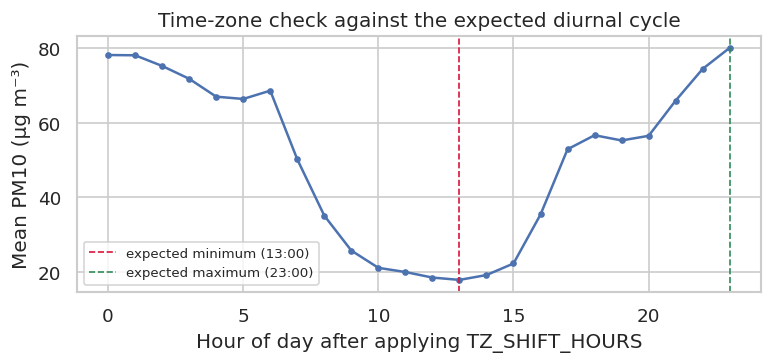

In [5]:
diurnal = raw.set_index("datetime")["pm10"].groupby(lambda t: t.hour).mean()
print(f"Hour of PM10 minimum : {int(diurnal.idxmin()):02d}:00   (expected near 13:00 WIB)")
print(f"Hour of PM10 maximum : {int(diurnal.idxmax()):02d}:00   (expected near 23:00 WIB)")
print(f"Current TZ_SHIFT_HOURS = {TZ_SHIFT_HOURS}")

plt.figure(figsize=(6.6, 3.2))
plt.plot(diurnal.index, diurnal.values, marker="o", ms=3)
plt.axvline(13, color="crimson", ls="--", lw=1, label="expected minimum (13:00)")
plt.axvline(23, color="seagreen", ls="--", lw=1, label="expected maximum (23:00)")
plt.xlabel("Hour of day after applying TZ_SHIFT_HOURS")
plt.ylabel(f"Mean PM10 ({UNIT})")
plt.title("Time-zone check against the expected diurnal cycle")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Pre-processing, quality control, and Table 1

> **Purpose.** Turn the raw records into (a) a regular hourly series with short gaps filled, (b) a documented chain of record counts, (c) a check of the temperature record, and (d) Table 1.
> **Output.** `df` (hourly grid, gaps visible), `df_i` (gaps of up to 3 h interpolated), `model_df` (complete records used for modeling), `n_train`, `tab1`.
> **What to check.** The record-count chain in 3.1, the diagnostic on long gaps, and the temperature diagnostics in 3.3.

### 3.1 Hourly grid, cleaning, and reconciliation of record counts

**Reviewer 3, comment 3.6.** The original submission quoted three record counts (6,182; 6,203; and a 4,962 + 1,241 split) without saying which applied where. All three were correct but described different stages of processing. The cell below prints the chain explicitly so that the figures in Section 2.2 of the manuscript can be verified.

The convention adopted in the revision (values for the reference data set):

- **6,222** slots on the regular hourly grid.
- **6,182** directly observed complete slots. Table 1 is computed on these, so that no interpolated value enters the distributional summary.
- **6,203** complete records after linear interpolation of short gaps. This is the modeling set, partitioned 4,962 / 1,241 into training and hold-out.

**Cleaning rules**

1. Duplicate timestamps are removed (first record kept), and the series is reindexed to every hour between the first and last record so that missing hours appear explicitly as NaN.
2. Negative PM values are physically impossible and are set to missing.
3. Gaps are filled by **time-based linear interpolation** (`limit=MAX_GAP_HOURS`, only *between* valid observations, never extrapolated at the ends). Pollutant and weather values change smoothly over a few hours, so this is a safe approximation.
4. Hours that are still missing are dropped from the modeling set.

Because a long gap could in principle be partly filled by the interpolation limit, the cell also reports how many hours inside gaps longer than `MAX_GAP_HOURS` were nevertheless filled.

In [6]:
df = raw.drop_duplicates(subset="datetime", keep="first").set_index("datetime")

full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h", name="datetime")
df = df.reindex(full_idx)
n_grid = len(df)

num_cols = ["pm1", "pm25", "pm10", "temp_c", "rh", "pressure"]
for c in TARGETS:
    df.loc[df[c] < 0, c] = np.nan       # physically implausible negative concentrations

n_raw_complete = int(df[num_cols].notna().all(axis=1).sum())
df_raw_complete = df[df[num_cols].notna().all(axis=1)].copy()   # basis for Table 1

# linear interpolation of short gaps, then removal of the remainder
df_i = df.copy()
df_i[num_cols] = df_i[num_cols].interpolate(method="time", limit=MAX_GAP_HOURS,
                                            limit_area="inside")
model_df = df_i[df_i[num_cols].notna().all(axis=1)].copy()
n_model = len(model_df)

n_train = int(round(n_model * SPLIT_FRAC))
n_test  = n_model - n_train

print(f"Slots on the hourly grid ............. {n_grid:,}")
print(f"Incomplete slots ..................... {n_grid - n_raw_complete:,} "
      f"({100 * (1 - n_raw_complete / n_grid):.2f}%)")
print(f"Directly observed complete (Table 1) . {n_raw_complete:,}")
print(f"Modelling set after interpolation .... {n_model:,}")
print(f"Chronological split .................. {n_train:,} train / {n_test:,} hold-out")
print(f"Split date ........................... {model_df.index[n_train]}")
print(f"Hold-out window ...................... {model_df.index[n_train]} to {model_df.index[-1]}")

# Diagnostic: were any hours inside gaps LONGER than MAX_GAP_HOURS partly filled?
miss_before = df[num_cols].isna().any(axis=1)
run_id = (miss_before != miss_before.shift()).cumsum()
run_len = miss_before.groupby(run_id).transform("sum")
in_long_gap = miss_before & (run_len > MAX_GAP_HOURS)
filled_in_long = int((in_long_gap & df_i[num_cols].notna().all(axis=1)).sum())
n_long_gaps = int(run_id[in_long_gap].nunique())
print(f"\nGaps longer than {MAX_GAP_HOURS} h ................ {n_long_gaps}")
print(f"Hours inside them that were still filled  {filled_in_long}")

Slots on the hourly grid ............. 6,222
Incomplete slots ..................... 40 (0.64%)
Directly observed complete (Table 1) . 6,182
Modelling set after interpolation .... 6,195
Chronological split .................. 4,956 train / 1,239 hold-out
Split date ........................... 2026-05-09 09:00:00
Hold-out window ...................... 2026-05-09 09:00:00 to 2026-06-29 23:00:00

Gaps longer than 3 h ................ 4
Hours inside them that were still filled  12


### 3.2 Where are the data missing?

The heatmap shows *when* values are missing before interpolation (orange cells), which helps judge whether the gaps are isolated or clustered.

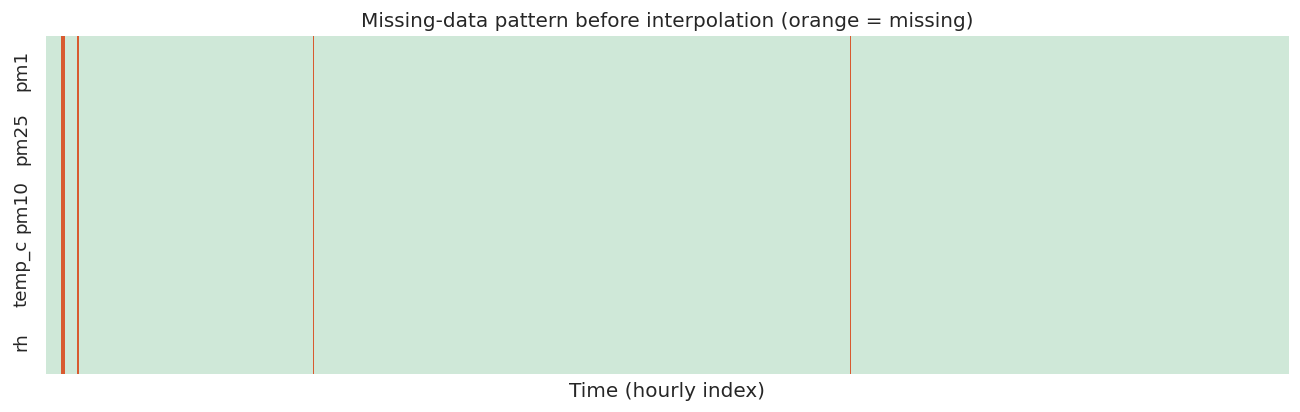

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(df[["pm1", "pm25", "pm10", "temp_c", "rh"]].isna().T,
            cbar=False, cmap=["#cfe8d8", "#d85a30"], xticklabels=False, ax=ax)
ax.set_title("Missing-data pattern before interpolation (orange = missing)")
ax.set_xlabel("Time (hourly index)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig01_missing_data_pattern.png", dpi=200, bbox_inches="tight")
plt.show()

### 3.3 Credibility of the recorded temperature maximum

**Reviewer 3, comment 3.7.** A maximum of 45 °C is not a credible ambient value for Pontianak, where the record maximum is several degrees lower, and is more consistent with radiative heating of an unshielded enclosure. Because temperature is one of the interpreted drivers, the extent and timing of the affected data are quantified here.

- A concentration of flagged hours around local solar noon supports the radiative interpretation, since a genuine ambient signal would not be confined so narrowly.
- Ambient air temperature over a tropical city peaks in the early to mid afternoon (13:00 to 15:00 WIB). A recorded maximum in the **morning** cannot be ambient; it indicates direct solar loading on the enclosure, most plausibly through an east-facing exposure.
- The printed counts populate the `‹n›` and `‹p›` placeholders in Section 3.1 of the manuscript.

Hours with T > 38.0 C : 224 (3.62% of the record)
Maximum recorded temperature : 45.0 C

Distribution of flagged hours by local hour (WIB):
datetime
7     14
8     84
9     70
10    33
11    15
12     4
13     4

Hour of mean maximum recorded temperature: 09:00 WIB
Expected for ambient air over a tropical city: 13:00 to 15:00 WIB.
The recorded maximum falls in the morning, which is not compatible with an
ambient signal and indicates direct solar loading on the sensor enclosure.


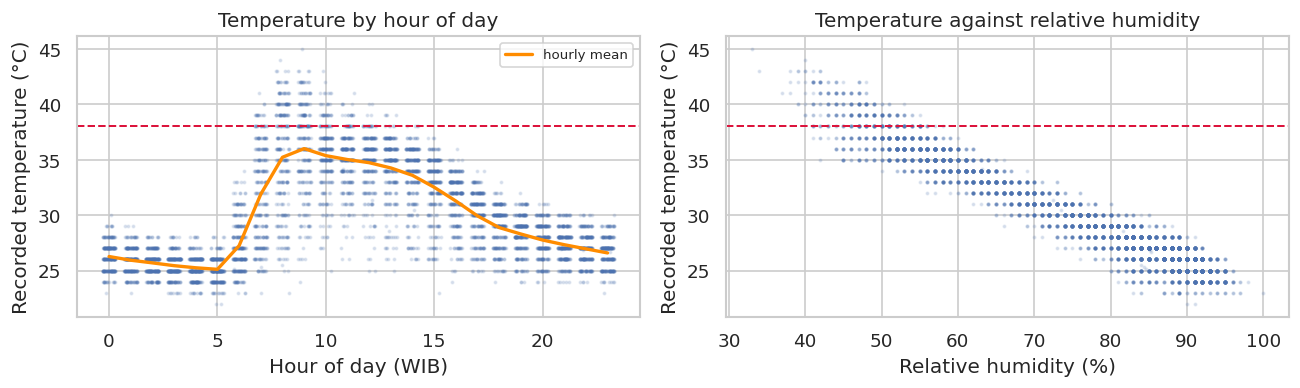

In [8]:
hot = model_df["temp_c"] > TEMP_FLAG
n_hot, p_hot = int(hot.sum()), 100 * hot.mean()
print(f"Hours with T > {TEMP_FLAG} C : {n_hot:,} ({p_hot:.2f}% of the record)")
print(f"Maximum recorded temperature : {model_df['temp_c'].max():.1f} C")

if n_hot:
    print("\nDistribution of flagged hours by local hour (WIB):")
    print(model_df.loc[hot].groupby(model_df.loc[hot].index.hour).size().to_string())
else:
    print(f"\nNo hours exceed {TEMP_FLAG} C. The screening test in Section 10 will return")
    print("identical results, and the <n> and <p> placeholders in Section 3.1 of the")
    print("manuscript may be reported as zero.")

hourly_t = model_df["temp_c"].groupby(model_df.index.hour).mean()
print(f"\nHour of mean maximum recorded temperature: {int(hourly_t.idxmax()):02d}:00 WIB")
print("Expected for ambient air over a tropical city: 13:00 to 15:00 WIB.")
if int(hourly_t.idxmax()) < 12:
    print("The recorded maximum falls in the morning, which is not compatible with an")
    print("ambient signal and indicates direct solar loading on the sensor enclosure.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].scatter(model_df.index.hour + np.random.default_rng(RANDOM_STATE).uniform(-.3, .3, len(model_df)),
              model_df["temp_c"], s=2, alpha=.15)
ax[0].axhline(TEMP_FLAG, color="crimson", lw=1.2, ls="--")
ax[0].plot(hourly_t.index, hourly_t.values, color="darkorange", lw=2, label="hourly mean")
ax[0].legend(fontsize=8)
ax[0].set_xlabel("Hour of day (WIB)"); ax[0].set_ylabel("Recorded temperature (°C)")
ax[0].set_title("Temperature by hour of day")
ax[1].scatter(model_df["rh"], model_df["temp_c"], s=2, alpha=.15)
ax[1].axhline(TEMP_FLAG, color="crimson", lw=1.2, ls="--")
ax[1].set_xlabel("Relative humidity (%)"); ax[1].set_ylabel("Recorded temperature (°C)")
ax[1].set_title("Temperature against relative humidity")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figA2_temperature_qc.png", dpi=200, bbox_inches="tight")
plt.show()

### 3.4 Table 1: descriptive statistics on the directly observed record

Statistics are computed on the directly observed complete records (6,182 in the reference data), not on the interpolated modeling set, so that no imputed value contributes to the distributional summary. The Table 1 caption in the manuscript states this convention.

In [9]:
tab1 = df_raw_complete[num_cols].agg(["mean", "std", "min", "median", "max"]).T
tab1.columns = ["Mean", "SD", "Min", "Med.", "Max"]
tab1 = tab1.round(1)
tab1.to_csv(f"{OUTPUT_DIR}/table1_descriptive.csv")
print(f"n = {len(df_raw_complete):,}")
tab1

n = 6,182


,Mean,SD,Min,Med.,Max
pm1,21.0,26.1,0.0,14.0,348.0
pm25,29.8,38.6,1.0,19.0,510.0
pm10,50.6,67.3,1.0,32.0,927.0
temp_c,29.8,4.5,22.0,29.0,45.0
rh,75.3,14.8,33.0,80.0,100.0
pressure,1007.5,1.9,1001.9,1007.5,1014.3


# Part B. Exploration and features

## 4. Exploratory data analysis (EDA)

> **Purpose.** See what the models will have to learn before building them: levels and episodes, skewness, daily and weekly rhythms, and relationships among variables.
> **Output.** Figures 02 to 06 in `outputs/`.
> **What to check.** Whether the three size fractions follow different daily curves. If they do, they are likely driven by different sources or processes, which is the motivation for modeling them separately.

All EDA figures use `df_i`, the hourly series after short-gap interpolation.

### 4.1 Time series
The full hourly record of the three fractions. Spikes mark pollution episodes (e.g., haze).

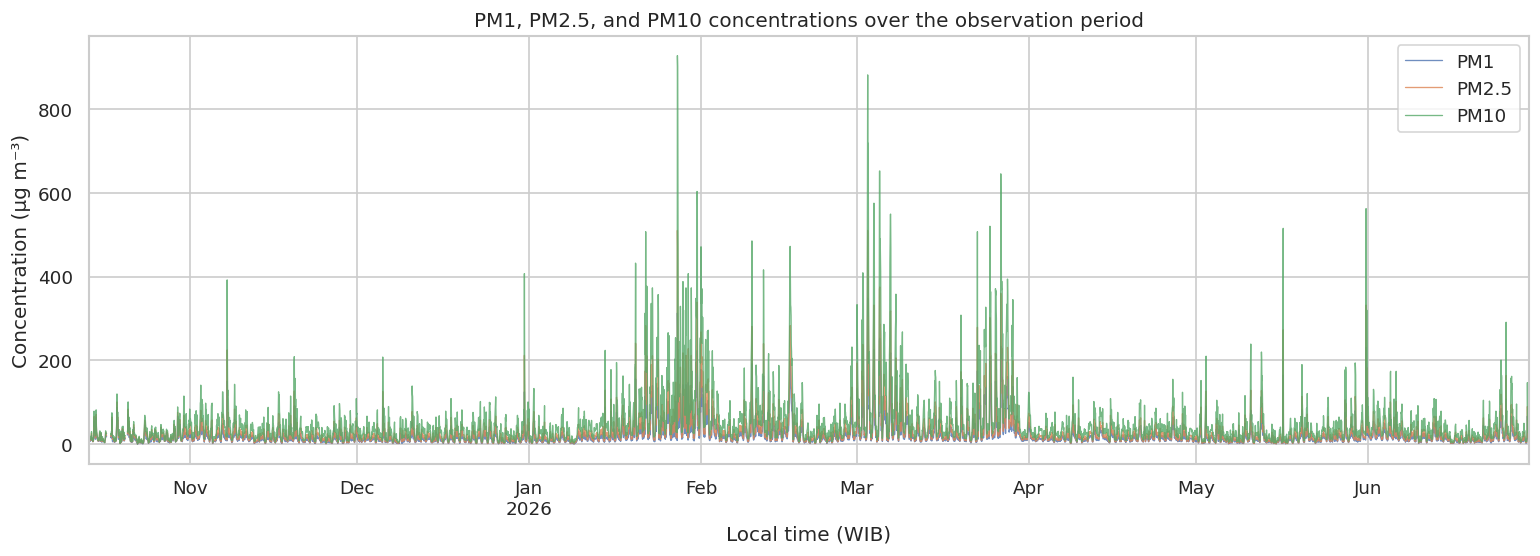

In [10]:
fig, ax = plt.subplots(figsize=(13, 4.8))
df_i[TARGETS].rename(columns=LABELS).plot(ax=ax, alpha=0.8, linewidth=0.8)
ax.set_title("PM1, PM2.5, and PM10 concentrations over the observation period")
ax.set_ylabel(f"Concentration ({UNIT})")
ax.set_xlabel("Local time (WIB)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig02_timeseries_pm.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.2 Distributions
Concentration distributions are typically right-skewed: most hours are relatively clean, while a few episodes reach very high values. This matters for error metrics, which are sensitive to those extremes.

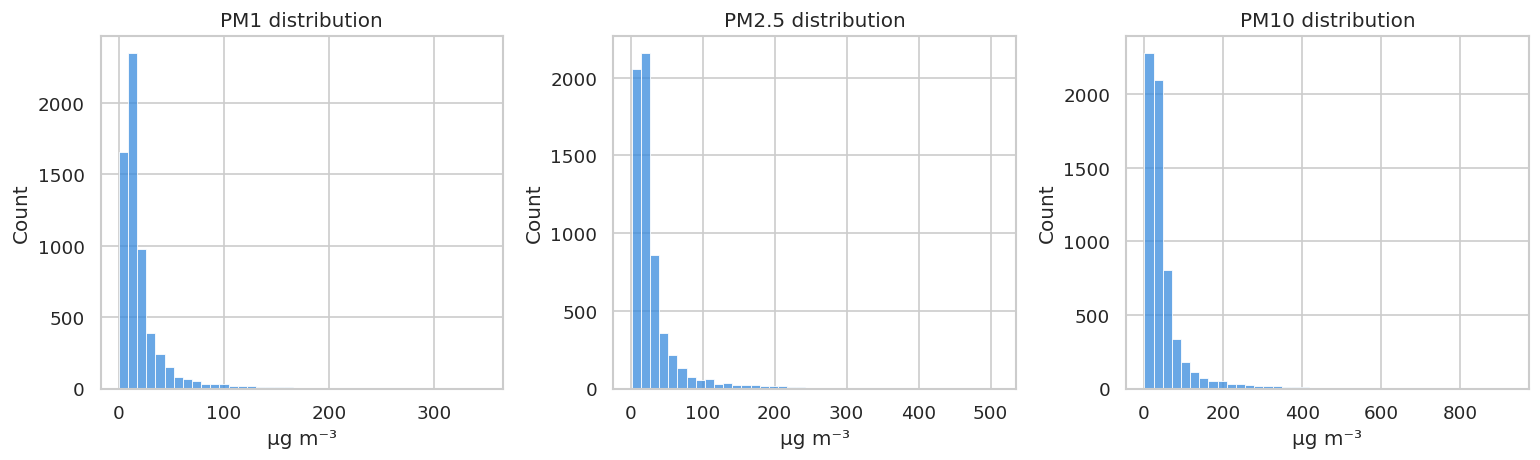

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, TARGETS):
    sns.histplot(df_i[col].dropna(), bins=40, ax=ax, color="#378ADD")
    ax.set_title(f"{LABELS[col]} distribution")
    ax.set_xlabel(UNIT)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig03_distribution_pm.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.3 Daily cycle
The mean concentration by hour of day reveals diurnal patterns (morning and evening peaks, nocturnal accumulation, afternoon dilution).

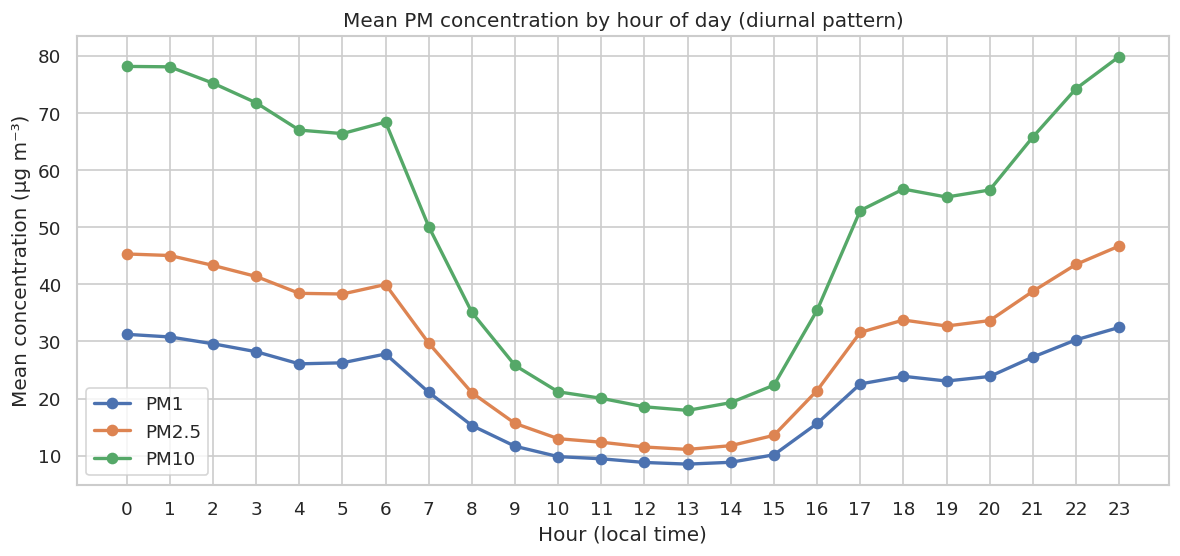

In [12]:
hourly_mean = df_i.groupby(df_i.index.hour)[TARGETS].mean().rename(columns=LABELS)

fig, ax = plt.subplots(figsize=(10, 4.8))
hourly_mean.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Mean PM concentration by hour of day (diurnal pattern)")
ax.set_xlabel("Hour (local time)")
ax.set_ylabel(f"Mean concentration ({UNIT})")
ax.set_xticks(range(24))
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig04_diurnal_pattern.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.4 Weekly cycle
Comparing weekdays with weekends hints at the role of human activity. A flat weekly profile means the weekly cycle carries little information; this becomes relevant for the `dow` feature in Section 13.

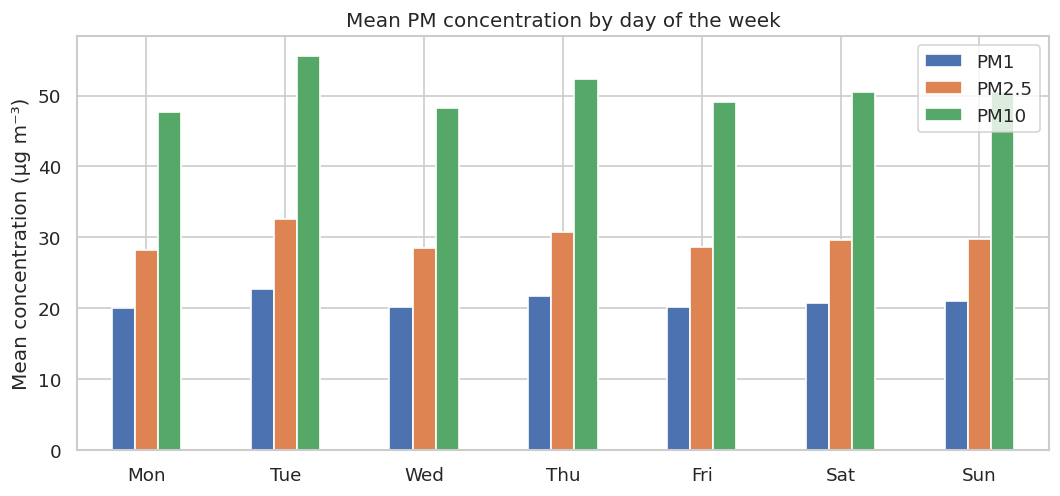

In [13]:
weekly_mean = df_i.groupby(df_i.index.dayofweek)[TARGETS].mean().rename(columns=LABELS)
weekly_mean.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(9, 4.3))
weekly_mean.plot(kind="bar", ax=ax)
ax.set_title("Mean PM concentration by day of the week")
ax.set_ylabel(f"Mean concentration ({UNIT})")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig05_weekly_pattern.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.5 Correlations
Strong correlation among the three PM fractions is expected (they are nested optical channels of the same sensor). What is informative is where their relationships with temperature, humidity, and pressure *differ*.

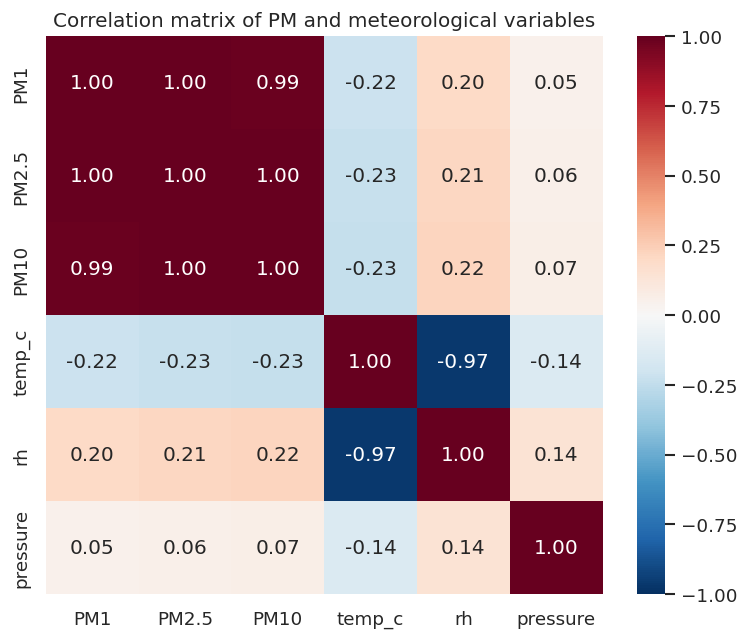

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
corr = df_i[num_cols].corr().rename(index=LABELS, columns=LABELS)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix of PM and meteorological variables")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig06_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Feature construction

> **Purpose.** Turn time and weather into the ten predictors the models use.
> **Output.** `X_all` (feature table aligned with `model_df`) and `y_all` (one target array per fraction).
> **What to check.** The `season_dry` message at the end (Reviewer 4, comment 4.2).

The models receive only information known *in advance* (calendar and weather), not lagged PM values. This is deliberate: the goal is to explain how time and weather relate to PM, not to forecast the next hour from the previous one.

| Feature | Description |
|---|---|
| `hour_sin`, `hour_cos` | Hour of day on a circle, so that 23:00 and 00:00 are neighbours |
| `month_sin`, `month_cos` | Month on a circle, so that December and January are neighbours |
| `dow`, `is_weekend` | Day of week (0 = Monday) and a weekend flag |
| `season_dry` | 1 for the simplified dry season (May–October), 0 for the wet season (November–April) |
| `temp_c`, `rh`, `pressure` | Temperature (°C), relative humidity (%), air pressure (hPa) |

**The `season_dry` check (Reviewer 4, comment 4.2).** The primary hold-out window lies between 9 May and 29 June 2026 and therefore falls entirely within the May–October dry season. If `season_dry` takes a single value across that window, no seasonal contrast can be recovered from it, and any seasonal attribution computed on the hold-out alone is uninterpretable. Section 11 therefore accumulates SHAP values *out-of-fold* across folds that span both seasons.

In [15]:
def build_features(d):
    X = pd.DataFrame(index=d.index)
    h, m = d.index.hour, d.index.month
    X["hour_sin"]   = np.sin(2 * np.pi * h / 24)
    X["hour_cos"]   = np.cos(2 * np.pi * h / 24)
    X["month_sin"]  = np.sin(2 * np.pi * m / 12)
    X["month_cos"]  = np.cos(2 * np.pi * m / 12)
    X["dow"]        = d.index.dayofweek
    X["is_weekend"] = (d.index.dayofweek >= 5).astype(int)
    X["season_dry"] = m.isin([5, 6, 7, 8, 9, 10]).astype(int)
    X["temp_c"]     = d["temp_c"].values
    X["rh"]         = d["rh"].values
    X["pressure"]   = d["pressure"].values
    return X


FEATURES = ["hour_sin", "hour_cos", "month_sin", "month_cos", "dow",
            "is_weekend", "season_dry", "temp_c", "rh", "pressure"]

X_all = build_features(model_df)[FEATURES]
y_all = {t: model_df[t].values for t in TARGETS}

print(f"Modeling set: {len(X_all):,} hours x {len(FEATURES)} features")

uniq = np.unique(X_all["season_dry"].values[n_train:])
print(f"\nUnique values of season_dry in the primary hold-out window: {uniq}")
if len(uniq) == 1:
    print("The indicator is constant across the hold-out window, confirming that a")
    print("dry-versus-wet contrast cannot be recovered from it. Section 11 uses")
    print("out-of-fold attribution across both seasons instead.")
X_all.head()

Modeling set: 6,195 hours x 10 features

Unique values of season_dry in the primary hold-out window: [1]
The indicator is constant across the hold-out window, confirming that a
dry-versus-wet contrast cannot be recovered from it. Section 11 uses
out-of-fold attribution across both seasons instead.


,hour_sin,hour_cos,month_sin,month_cos,dow,is_weekend,season_dry,temp_c,rh,pressure
datetime,,,,,,,,,,
2025-10-13 18:00:00,-1.000000,-1.836970e-16,-0.866025,0.5,0,0,1,31.0,72.0,1008.86
2025-10-13 19:00:00,-0.965926,2.588190e-01,-0.866025,0.5,0,0,1,31.0,71.0,1009.21
2025-10-13 20:00:00,-0.866025,5.000000e-01,-0.866025,0.5,0,0,1,30.0,71.0,1009.48
2025-10-13 21:00:00,-0.707107,7.071068e-01,-0.866025,0.5,0,0,1,30.0,71.0,1009.62
2025-10-13 22:00:00,-0.500000,8.660254e-01,-0.866025,0.5,0,0,1,29.0,71.0,1009.61


# Part C. Models

## 6. Modeling design and baseline (as-submitted) models

> **Purpose.** Define how models are trained and scored, and reproduce the *original* (as-submitted) results as a reference point.
> **Output.** `baseline_rows`, a table of hold-out scores for the three learners × three fractions with their original settings.
> **What to check.** The R² values under the two baseline conventions, and the dispersion of training versus hold-out windows.

**One model per particle size.** PM1, PM2.5, and PM10 are modeled separately so that their SHAP attributions can be compared fairly in Section 11. Because the three targets are nested optical channels of one sensor, they are near-collinear by construction, so the per-fraction models are not independent analyses.

**Chronological split.** The first `SPLIT_FRAC` (80 %) of the timeline trains the model and the last 20 % tests it. A random split is avoided because neighbouring hours are highly similar: random splitting would place near-copies of test hours in the training set (data leakage) and give overly optimistic scores.

**Learners.** Random Forest, LightGBM, and XGBoost: tree-based models that work well on tabular data and are compatible with SHAP's fast `TreeExplainer`.

**Metrics** (on the hold-out set)

- **RMSE**: typical error size in µg m⁻³; penalizes large errors more.
- **MAE**: average absolute error in µg m⁻³; less sensitive to extreme episodes.
- **R²**: share of variance explained, reported under two baseline conventions because they differ materially for this record: the hold-out window is considerably quieter than the training period, so referencing the training mean flatters the models.
  - `R2_window` is referenced to the mean of the evaluation window itself. This is the stricter convention (a negative value means the model is less accurate than the local mean) and **the one reported in Table 2 of the manuscript**.
  - `R2_trainmean` is referenced to the mean of the training period.

**Baseline configurations.** The settings of the original submission are reproduced below without tuning or early stopping, so that the negative R² of the original XGBoost can be reproduced and its origin verified rather than merely asserted.

In [16]:
Xtr_all, Xte_all = X_all.iloc[:n_train], X_all.iloc[n_train:]

AS_SUBMITTED = {
    "Random Forest": dict(n_estimators=400, max_depth=None, min_samples_leaf=2),
    "LightGBM":      dict(n_estimators=500, max_depth=-1, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8),
    "XGBoost":       dict(n_estimators=500, max_depth=6, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8),
}


def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))


def r2_vs(y, yhat, reference):
    """R2 with an explicit baseline: 1 - SSE / sum((y - reference)^2)."""
    return float(1 - np.sum((y - yhat) ** 2) / np.sum((y - reference) ** 2))


def fit_plain(name, p, Xtr, ytr, seed=RANDOM_STATE):
    """Fit a configuration exactly as given (no early stopping)."""
    if name == "Random Forest":
        m = RandomForestRegressor(random_state=seed, n_jobs=-1, **p)
    elif name == "LightGBM":
        m = lgb.LGBMRegressor(random_state=seed, n_jobs=-1, verbose=-1, **p)
    else:
        m = xgb.XGBRegressor(random_state=seed, n_jobs=-1, tree_method="hist", **p)
    m.fit(Xtr, ytr)
    return m


def holdout_row(t, name, config, ytr, yte, yhat):
    return dict(Fraction=t, Model=name, Config=config,
                RMSE=round(rmse(yte, yhat), 2),
                MAE=round(float(mean_absolute_error(yte, yhat)), 2),
                R2_window=round(r2_vs(yte, yhat, yte.mean()), 3),
                R2_trainmean=round(r2_vs(yte, yhat, ytr.mean()), 3))


baseline_rows = []
for t in TARGETS:
    ytr, yte = y_all[t][:n_train], y_all[t][n_train:]
    for name in LEARNER_NAMES:
        m = fit_plain(name, AS_SUBMITTED[name], Xtr_all, ytr)
        baseline_rows.append(holdout_row(t, name, "as-submitted", ytr, yte, m.predict(Xte_all)))

print(f"Training : {n_train:,} hours ({Xtr_all.index.min():%Y-%m-%d} to {Xtr_all.index.max():%Y-%m-%d})")
print(f"Hold-out : {n_test:,} hours ({Xte_all.index.min():%Y-%m-%d} to {Xte_all.index.max():%Y-%m-%d})")

print("\nDispersion of the training and hold-out windows, which is why the two")
print("baseline conventions for R2 diverge:")
for t in TARGETS:
    print(f"  {t:>5}: training SD {y_all[t][:n_train].std():7.2f} | "
          f"hold-out SD {y_all[t][n_train:].std():7.2f}")

print("\nAs-submitted configurations on the primary hold-out:")
pd.DataFrame(baseline_rows).sort_values(["Fraction", "R2_window"], ascending=[True, False]).reset_index(drop=True)

Training : 4,956 hours (2025-10-13 to 2026-05-09)
Hold-out : 1,239 hours (2026-05-09 to 2026-06-29)

Dispersion of the training and hold-out windows, which is why the two
baseline conventions for R2 diverge:
    pm1: training SD   27.88 | hold-out SD   16.07
   pm25: training SD   41.26 | hold-out SD   23.37
   pm10: training SD   72.05 | hold-out SD   40.38

As-submitted configurations on the primary hold-out:


,Fraction,Model,Config,RMSE,MAE,R2_window,R2_trainmean
0,pm1,Random Forest,as-submitted,14.36,7.78,0.202,0.305
1,pm1,LightGBM,as-submitted,15.00,8.61,0.129,0.241
2,pm1,XGBoost,as-submitted,15.97,9.18,0.012,0.140
3,pm10,Random Forest,as-submitted,36.52,18.46,0.182,0.294
4,pm10,LightGBM,as-submitted,38.67,20.69,0.083,0.208
5,pm10,XGBoost,as-submitted,41.84,23.25,-0.074,0.073
6,pm25,Random Forest,as-submitted,20.97,10.97,0.195,0.306
7,pm25,LightGBM,as-submitted,22.17,12.41,0.101,0.225
8,pm25,XGBoost,as-submitted,24.17,13.68,-0.069,0.078


## 7. Hyper-parameter search on an equal footing

> **Purpose.** Give each learner the same tuning effort, so that differences between learners are not artefacts of unequal settings.
> **Output.** `BEST` (selected hyper-parameters per fraction and learner), `NTREES` (tree count retained by early stopping), and `outputs/best_hyperparameters.json`.
> **What to check.** The inner-CV RMSE printed for each fraction and learner; very different values between learners would signal a problem.

**Reviewer 3, comment 3.3.** In the original submission Random Forest was fitted with 400 trees under minimal constraint, whereas both gradient-boosting machines were fixed at 500 trees with a learning rate of 0.05, without early stopping and without tuning. The comparison was therefore not on equal terms, and the negative R² returned by XGBoost is the expected consequence of an imposed rather than selected tree budget.

**Procedure**

1. Each learner receives a randomised search of identical size (`N_SEARCH` candidates) over the number of trees, tree depth, leaf size, learning rate, and row/column subsampling.
2. Each candidate is scored by an **inner rolling-origin cross-validation** (3 expanding-window folds) within the *training period only*. Scoring on a single trailing window proved unreliable, because that window coincides with the tail of the January to March episode cluster and ranked candidates on an unrepresentative period. Averaging over several folds gives a more stable ranking at proportionate cost.
3. The boosting machines use early stopping inside each inner fold, so their effective number of trees is *selected* rather than fixed. The median retained tree count is recorded.
4. The selected configuration is **refitted on the full training set** with that tree count fixed (`fit_final`). Early stopping needs a validation split, but a model fitted on a subset never sees the period immediately preceding the evaluation window, which is the most informative one for a chronological series.

In [17]:
RF_GRID = dict(n_estimators=[300, 400, 600, 800],
               max_depth=[None, 12, 20, 30],
               min_samples_leaf=[1, 2, 4, 8],
               max_features=["sqrt", 0.5, 0.8, 1.0])
GB_GRID = dict(n_estimators=[2000],                       # upper bound; early stopping selects
               learning_rate=[0.01, 0.03, 0.05, 0.1],
               max_depth=[4, 6, 8, 10],
               subsample=[0.7, 0.8, 1.0],
               colsample_bytree=[0.7, 0.8, 1.0],
               min_child_weight=[1, 5, 20])


def sample_grid(grid, n, rng):
    keys = list(grid)
    return [{k: grid[k][rng.integers(len(grid[k]))] for k in keys} for _ in range(n)]


def fit_rf(p, Xtr, ytr, Xva=None, yva=None, seed=0):
    m = RandomForestRegressor(random_state=seed, n_jobs=-1, **p)
    m.fit(Xtr, ytr)
    return m


def fit_lgb(p, Xtr, ytr, Xva, yva, seed=0):
    m = lgb.LGBMRegressor(random_state=seed, n_jobs=-1, verbose=-1, **p)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="rmse",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m


def fit_xgb(p, Xtr, ytr, Xva, yva, seed=0):
    try:
        m = xgb.XGBRegressor(random_state=seed, n_jobs=-1, tree_method="hist",
                             early_stopping_rounds=100, **p)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    except TypeError:                       # older XGBoost API
        m = xgb.XGBRegressor(random_state=seed, n_jobs=-1, tree_method="hist", **p)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], early_stopping_rounds=100, verbose=False)
    return m


LEARNERS = {"Random Forest": (RF_GRID, fit_rf),
            "LightGBM":      (GB_GRID, fit_lgb),
            "XGBoost":       (GB_GRID, fit_xgb)}


def best_iteration(m, fallback):
    """Number of trees actually retained after early stopping."""
    for attr in ("best_iteration_", "best_iteration"):
        v = getattr(m, attr, None)
        if v:
            return int(v)
    return fallback


def tune(name, Xtr, ytr, seed=RANDOM_STATE, n_inner=3):
    """Randomised search scored over an inner rolling-origin split."""
    grid, fitter = LEARNERS[name]
    rng = np.random.default_rng(seed)
    inner = TimeSeriesSplit(n_splits=n_inner)
    best, best_score, best_iters = None, np.inf, None
    for p in sample_grid(grid, N_SEARCH, rng):
        scores, iters = [], []
        for tr, va in inner.split(Xtr):
            try:
                m = fitter(p, Xtr.iloc[tr], ytr[tr], Xtr.iloc[va], ytr[va], seed)
                scores.append(rmse(ytr[va], m.predict(Xtr.iloc[va])))
                iters.append(best_iteration(m, p.get("n_estimators", 500)))
            except Exception:
                scores.append(np.inf)
        s = float(np.mean(scores))
        if s < best_score:
            best_score, best, best_iters = s, p, iters
    n_final = int(np.median(best_iters)) if best_iters else None
    return best, best_score, n_final


def fit_final(name, p, X, y, seed=RANDOM_STATE, n_trees=None):
    """Refit the selected configuration on ALL given training data, with the
    tree count chosen by early stopping held fixed."""
    p = dict(p)
    if name == "Random Forest":
        m = RandomForestRegressor(random_state=seed, n_jobs=-1, **p)
    else:
        if n_trees:
            p["n_estimators"] = n_trees
        if name == "LightGBM":
            m = lgb.LGBMRegressor(random_state=seed, n_jobs=-1, verbose=-1, **p)
        else:
            m = xgb.XGBRegressor(random_state=seed, n_jobs=-1, tree_method="hist", **p)
    m.fit(X, y)
    return m

In [18]:
BEST, NTREES = {}, {}
for t in TARGETS:
    ytr = y_all[t][:n_train]
    BEST[t], NTREES[t] = {}, {}
    for name in LEARNER_NAMES:
        p, s, n_final = tune(name, Xtr_all, ytr, RANDOM_STATE)
        BEST[t][name], NTREES[t][name] = p, n_final
        extra = "" if name == "Random Forest" else f" | trees retained {n_final}"
        print(f"{t:>5} | {name:<14} inner-CV RMSE {s:7.3f}{extra}")
        print(f"        {p}")

with open(f"{OUTPUT_DIR}/best_hyperparameters.json", "w") as f:
    json.dump({"params": BEST, "n_trees": NTREES}, f, indent=2, default=str)

  pm1 | Random Forest  inner-CV RMSE  29.295
        {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 8, 'max_features': 'sqrt'}
  pm1 | LightGBM       inner-CV RMSE  27.110 | trees retained 13
        {'n_estimators': 2000, 'learning_rate': 0.1, 'max_depth': 6, 'subsample': 1.0, 'colsample_bytree': 1.0, 'min_child_weight': 20}
  pm1 | XGBoost        inner-CV RMSE  27.033 | trees retained 122
        {'n_estimators': 2000, 'learning_rate': 0.01, 'max_depth': 8, 'subsample': 0.7, 'colsample_bytree': 1.0, 'min_child_weight': 20}
 pm25 | Random Forest  inner-CV RMSE  43.925
        {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 8, 'max_features': 'sqrt'}
 pm25 | LightGBM       inner-CV RMSE  40.324 | trees retained 23
        {'n_estimators': 2000, 'learning_rate': 0.1, 'max_depth': 6, 'subsample': 1.0, 'colsample_bytree': 1.0, 'min_child_weight': 20}
 pm25 | XGBoost        inner-CV RMSE  40.224 | trees retained 26
        {'n_estimators': 2000, 'learning_rate': 0.05

## 8. Table 2: hold-out performance with both R² conventions

> **Purpose.** Evaluate the tuned models on the primary hold-out and compare them with the as-submitted baseline.
> **Output.** `tab2` (saved as `table2_holdout.csv`), the fitted tuned models in `FITTED`, and Figures 07 and 08.
> **What to check.** Whether tuning changed the picture (especially the negative R² of the original XGBoost), and how `R2_window` compares with `R2_trainmean`.

**Reviewer 1 comment 1.1, Reviewer 3 comment 3.2, and Reviewer 4 comment 4.1.** The coefficient of determination is reported for every model–fraction combination under both baseline conventions defined in Section 6. A negative `R2_window` denotes a model less accurate than the local climatological mean of the evaluation window.

In [19]:
tuned_rows, FITTED = [], {}
for t in TARGETS:
    ytr, yte = y_all[t][:n_train], y_all[t][n_train:]
    for name in LEARNER_NAMES:
        m = fit_final(name, BEST[t][name], Xtr_all, ytr, RANDOM_STATE, NTREES[t][name])
        tuned_rows.append(holdout_row(t, name, "tuned", ytr, yte, m.predict(Xte_all)))
        FITTED[(t, name)] = m

tab2 = pd.DataFrame(baseline_rows + tuned_rows)
tab2.to_csv(f"{OUTPUT_DIR}/table2_holdout.csv", index=False)

display(tab2.pivot_table(index=["Fraction", "Model"], columns="Config",
                         values=["RMSE", "MAE", "R2_window", "R2_trainmean"]))

MAE        R2_trainmean           R2_window  \
Config                 as-submitted  tuned as-submitted  tuned as-submitted   
Fraction Model                                                                
pm1      LightGBM              8.61   8.66        0.241  0.266        0.129   
         Random Forest         7.78   7.59        0.305  0.309        0.202   
         XGBoost               9.18   8.28        0.140  0.294        0.012   
pm10     LightGBM             20.69  20.10        0.208  0.272        0.083   
         Random Forest        18.46  18.13        0.294  0.283        0.182   
         XGBoost              23.25  18.81        0.073  0.287       -0.074   
pm25     LightGBM             12.41  11.65        0.225  0.277        0.101   
         Random Forest        10.97  10.73        0.306  0.305        0.195   
         XGBoost              13.68  11.97        0.078  0.285       -0.069   

                                      RMSE         
Config                  tuned as-submitted  tuned  
Fraction Model                                     
pm1      LightGBM       0.158        15.00  14.75  
         Random Forest  0.206        14.36  14.32  
         XGBoost        0.190        15.97  14.47  
pm10     LightGBM       0.157        38.67  37.08  
         Random Forest  0.169        36.52  36.81  
         XGBoost        0.175        41.84  36.68  
pm25     LightGBM       0.162        22.17  21.40  
         Random Forest  0.194        20.97  20.99  
         XGBoost        0.170        24.17  21.29

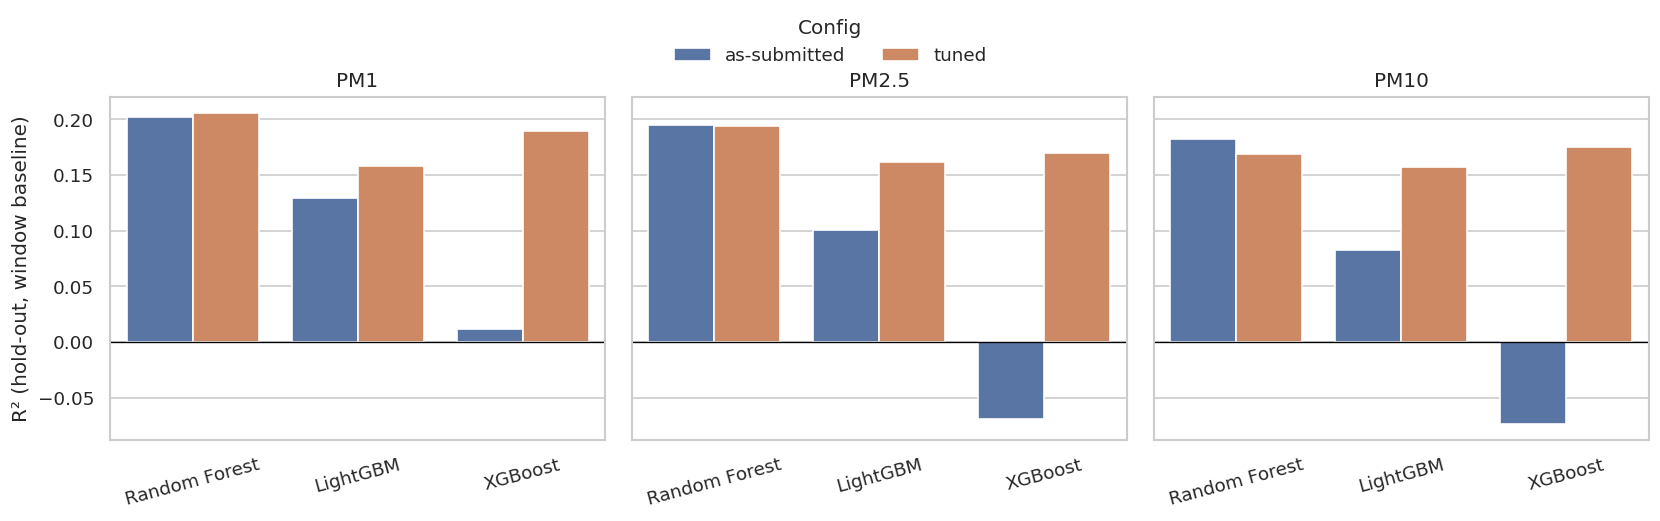

In [20]:
# Figure 07: R2 (window baseline) before and after tuning
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, t in zip(axes, TARGETS):
    sub = tab2[tab2["Fraction"] == t]
    sns.barplot(data=sub, x="Model", y="R2_window", hue="Config", ax=ax)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(LABELS[t])
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    if ax is not axes[0]:
        ax.set_ylabel("")
handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    ax.get_legend().remove()
fig.legend(handles, labels, title="Config", loc="upper center", ncol=2,
           bbox_to_anchor=(0.5, 1.10), frameon=False)
axes[0].set_ylabel("R² (hold-out, window baseline)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig07_model_comparison_r2.png", dpi=200, bbox_inches="tight")
plt.show()

**Predicted versus observed.** A visual check of the tuned Random Forest over the hold-out period (the same model family that is explained with SHAP in Section 11). It shows whether the model follows the general level and rhythm, and where it misses episodes.

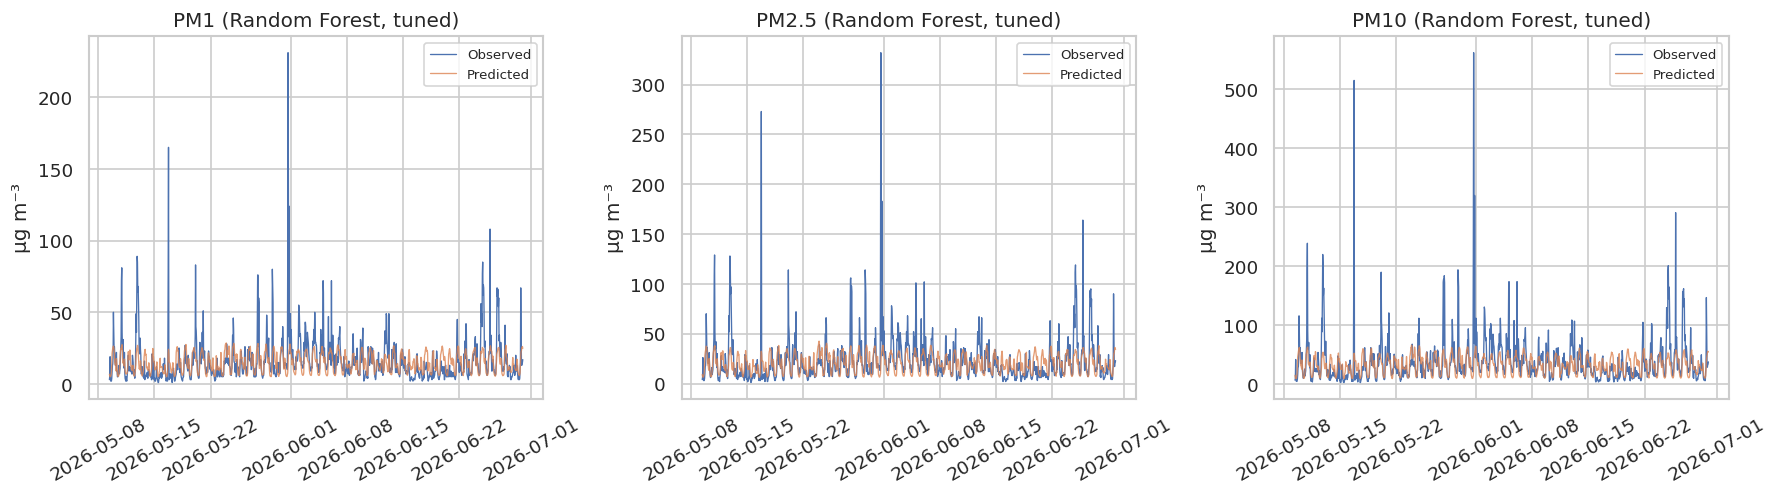

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, t in zip(axes, TARGETS):
    yhat = FITTED[(t, "Random Forest")].predict(Xte_all)
    ax.plot(Xte_all.index, y_all[t][n_train:], label="Observed", linewidth=0.8)
    ax.plot(Xte_all.index, yhat, label="Predicted", linewidth=0.8, alpha=0.8)
    ax.set_title(f"{LABELS[t]} (Random Forest, tuned)")
    ax.set_ylabel(UNIT)
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig08_prediction_vs_observed.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Rolling-origin cross-validation and interval estimation

> **Purpose.** Test whether any learner is *consistently* better than the others, rather than relying on one split.
> **Output.** `cv` (every run), `summary` (mean ± SD per fraction and learner, saved as `table2_cv_summary.csv`), and `oof_store` (Random Forest models and their test rows per fold, used for SHAP in Section 11).
> **What to check.** The paired contrasts in 9.2: where the interval contains zero, no ranking should be asserted.

**Reviewer 1 comment 1.1 and Reviewer 3 comment 3.3.** Differences of 5 to 15 per cent in RMSE on a single chronological split, without repeated seeds or any interval, do not support a claim that one learner consistently outperforms the others.

The protocol is therefore repeated over `N_FOLDS` (5) **expanding-window folds**, which respect temporal ordering and involve no shuffling, and over `N_SEEDS` (10) random seeds within each fold. Contrasts between learners are evaluated on *paired per-fold differences* rather than on a single aggregate, and a bootstrap interval is computed for each contrast.

### 9.1 Run the cross-validation

This cell fits 3 fractions × 5 folds × 3 learners × 10 seeds = **450 models** and is the principal computational cost of the notebook. Reduce `N_SEEDS` for a trial run.

In [22]:
tscv = TimeSeriesSplit(n_splits=N_FOLDS)
cv_rows, oof_store = [], {t: [] for t in TARGETS}

for t in TARGETS:
    y = y_all[t]
    for fi, (tr_idx, te_idx) in enumerate(tscv.split(X_all)):
        Xtr, Xte = X_all.iloc[tr_idx], X_all.iloc[te_idx]
        ytr, yte = y[tr_idx], y[te_idx]
        for name in LEARNER_NAMES:
            for seed in range(N_SEEDS):
                m = fit_final(name, BEST[t][name], Xtr, ytr, seed, NTREES[t][name])
                yhat = m.predict(Xte)
                cv_rows.append(dict(Fraction=t, Model=name, fold=fi, seed=seed,
                                    RMSE=rmse(yte, yhat),
                                    MAE=float(mean_absolute_error(yte, yhat)),
                                    R2_window=r2_vs(yte, yhat, yte.mean())))
                if name == "Random Forest" and seed == 0:
                    oof_store[t].append((fi, m, Xte))
    print(f"completed: {t}")

cv = pd.DataFrame(cv_rows)
cv.to_csv(f"{OUTPUT_DIR}/cv_raw_runs.csv", index=False)

summary = (cv.groupby(["Fraction", "Model"])
             .agg(RMSE_mean=("RMSE", "mean"), RMSE_sd=("RMSE", "std"),
                  MAE_mean=("MAE", "mean"),
                  R2_mean=("R2_window", "mean"), R2_sd=("R2_window", "std"))
             .round(3).reset_index())
summary["RMSE_CV"] = (summary["RMSE_mean"].round(2).astype(str) + " +/- "
                      + summary["RMSE_sd"].round(2).astype(str))
summary.to_csv(f"{OUTPUT_DIR}/table2_cv_summary.csv", index=False)
summary

completed: pm1
completed: pm25
completed: pm10


,Fraction,Model,RMSE_mean,RMSE_sd,MAE_mean,R2_mean,R2_sd,RMSE_CV
0,pm1,LightGBM,22.899,13.470,13.771,-0.005,0.212,22.9 +/- 13.47
1,pm1,Random Forest,23.273,13.041,14.190,-0.105,0.402,23.27 +/- 13.04
2,pm1,XGBoost,23.008,13.751,13.787,-0.002,0.213,23.01 +/- 13.75
3,pm10,LightGBM,58.819,35.642,34.576,0.006,0.247,58.82 +/- 35.64
4,pm10,Random Forest,59.426,34.853,35.193,-0.053,0.330,59.43 +/- 34.85
5,pm10,XGBoost,58.588,35.921,34.160,0.027,0.203,58.59 +/- 35.92
6,pm25,LightGBM,33.728,20.090,19.928,0.002,0.212,33.73 +/- 20.09
7,pm25,Random Forest,34.292,19.707,20.560,-0.086,0.391,34.29 +/- 19.71
8,pm25,XGBoost,34.165,20.352,20.219,-0.028,0.256,34.16 +/- 20.35


### 9.2 Paired contrasts between learners

For each fraction, the RMSE of LightGBM and XGBoost is compared with Random Forest fold by fold (seed-averaged). A bootstrap over the fold-level differences gives a 95 % interval. A *positive* difference favours Random Forest.

Where the interval contains zero, the statement in Section 3.4 of the manuscript that the intervals for the three learners overlap is supported, and no ranking should be asserted.

In [23]:
piv = cv.groupby(["Fraction", "Model", "fold"])["RMSE"].mean().unstack("Model")
rng = np.random.default_rng(RANDOM_STATE)

print("RMSE difference relative to Random Forest (positive favours Random Forest)\n")
for t in TARGETS:
    sub = piv.loc[t]
    for other in ["LightGBM", "XGBoost"]:
        d = (sub[other] - sub["Random Forest"]).values
        boot = [np.mean(rng.choice(d, len(d), replace=True)) for _ in range(5000)]
        lo, hi = np.percentile(boot, [2.5, 97.5])
        if lo > 0:
            verdict = "Random Forest favoured"
        elif hi < 0:
            verdict = "Random Forest disfavoured"
        else:
            verdict = "intervals overlap"
        print(f"{t:>5}  Random Forest vs {other:<9} delta = {d.mean():+6.2f}  "
              f"95% CI [{lo:+6.2f}, {hi:+6.2f}]  -> {verdict}")

RMSE difference relative to Random Forest (positive favours Random Forest)

  pm1  Random Forest vs LightGBM  delta =  -0.37  95% CI [ -1.69,  +0.44]  -> intervals overlap
  pm1  Random Forest vs XGBoost   delta =  -0.26  95% CI [ -1.76,  +0.92]  -> intervals overlap
 pm25  Random Forest vs LightGBM  delta =  -0.56  95% CI [ -2.31,  +0.44]  -> intervals overlap
 pm25  Random Forest vs XGBoost   delta =  -0.13  95% CI [ -1.54,  +1.07]  -> intervals overlap
 pm10  Random Forest vs LightGBM  delta =  -0.61  95% CI [ -2.25,  +0.47]  -> intervals overlap
 pm10  Random Forest vs XGBoost   delta =  -0.84  95% CI [ -3.68,  +0.68]  -> intervals overlap


## 10. Sensitivity to screening of radiatively affected hours

> **Purpose.** Check whether the suspect high-temperature hours (Section 3.3) materially affect the results.
> **Output.** Relative change in RMSE and the five most important features after screening.
> **What to check.** A small RMSE change and an unchanged top-five ranking mean the flagged hours do not drive the conclusions.

**Reviewer 3, comment 3.7.** Because temperature is one of the interpreted drivers, the Random Forest models are refitted with the flagged hours removed. Reporting the change in error alongside the feature ranking lets readers judge whether the affected hours matter, rather than asking them to accept the assertion. The relative change in RMSE populates the `‹x›` placeholder in Section 3.4 of the manuscript.

Features are ranked by mean absolute SHAP for comparability with Table 3; impurity-based importances are not comparable across configurations and are diluted by feature subsampling.

In [24]:
keep = ~(X_all["temp_c"] > TEMP_FLAG).values
Xs, n_train_s = X_all[keep], int(round(keep.sum() * SPLIT_FRAC))
print(f"Records retained after screening: {keep.sum():,} ({(~keep).sum():,} removed)\n")

for t in TARGETS:
    ys = y_all[t][keep]
    m = fit_final("Random Forest", BEST[t]["Random Forest"],
                  Xs.iloc[:n_train_s], ys[:n_train_s], RANDOM_STATE)
    r_screened = rmse(ys[n_train_s:], m.predict(Xs.iloc[n_train_s:]))
    r_reference = float(tab2.query(
        "Fraction == @t and Model == 'Random Forest' and Config == 'tuned'")["RMSE"].iloc[0])
    print(f"{t:>5}: RMSE {r_reference:6.2f} -> {r_screened:6.2f}  "
          f"(change {100 * (r_screened - r_reference) / r_reference:+.1f}%)")

    sv = np.abs(shap.TreeExplainer(m).shap_values(
        Xs.iloc[n_train_s:].head(SHAP_MAX_ROWS or 800), check_additivity=False)).mean(0)
    imp = pd.Series(sv, index=FEATURES).sort_values(ascending=False)
    print("       five most important features: " + ", ".join(imp.index[:5]) + "\n")

Records retained after screening: 5,971 (224 removed)

  pm1: RMSE  14.32 ->  14.54  (change +1.5%)
       five most important features: hour_cos, month_cos, month_sin, rh, season_dry

 pm25: RMSE  20.99 ->  21.30  (change +1.5%)
       five most important features: hour_cos, month_cos, season_dry, month_sin, rh

 pm10: RMSE  36.81 ->  37.23  (change +1.1%)
       five most important features: hour_cos, season_dry, month_cos, month_sin, rh



# Part D. Interpretation

## 11. Out-of-fold SHAP attribution

> **Purpose.** Explain what drives the predictions for each particle size, and compare the fractions, with uncertainty.
> **Output.** `shap_pool` / `X_pool` (pooled out-of-fold attributions), Table 3, bootstrap intervals, and Figures 09, A1, 10, 11.
> **What to check.** `season_dry` takes both values in the pooled data; the interval on the PM1 − PM10 difference; and whether the printed feature orderings agree with Table 3.

**What SHAP does.** For every single prediction, SHAP splits the difference between that prediction and the average prediction into one contribution per feature. A positive value pushes the predicted concentration up; a negative one pushes it down. Averaging absolute contributions over many hours gives a global ranking of features.

**Reading tips**

- SHAP explains what the *model* has learned. Its reliability depends on how well the model performs (Section 8).
- Cyclical pairs (`hour_sin`/`hour_cos`, `month_sin`/`month_cos`) together encode a single variable (time of day, time of year). Interpret each pair jointly, not each member alone.
- SHAP shares credit among correlated features (e.g., temperature and humidity).

**Reviewer 3 comment 3.4 and Reviewer 4 comment 4.2** are addressed together:

1. Attributions are accumulated *out-of-fold* across the rolling-origin folds rather than computed on the primary hold-out alone. Because that window lies entirely within the dry season (Section 5), the seasonal term could not otherwise be evaluated where it varies.
2. The attribution shares behind the size-dependence claim receive non-parametric bootstrap intervals over instances. The claim in question is a difference of about three percentage points in meteorological share between PM1 and PM10, previously reported without any uncertainty. The interval on that difference populates the `‹±a›` and `‹±b›` placeholders in Section 3.5.

Interpretation should remain conservative in either case: the three targets are near-collinear by construction (Section 6).

### 11.1 Compute out-of-fold SHAP values

For each fraction and fold, the Random Forest stored in Section 9 explains (a subsample of) *its own test rows*, i.e., data it never saw during training. The rows are pooled over folds.

In [25]:
MET = ["temp_c", "rh", "pressure"]
shap_pool, X_pool = {}, {}


def shap_subsample(X, seed):
    """Draw at most SHAP_MAX_ROWS rows, preserving chronological order."""
    if not SHAP_MAX_ROWS or len(X) <= SHAP_MAX_ROWS:
        return X
    sel = np.random.default_rng(seed).choice(len(X), SHAP_MAX_ROWS, replace=False)
    return X.iloc[np.sort(sel)]


def tree_shap(model, X):
    return shap.TreeExplainer(model).shap_values(X, check_additivity=False)


for t in TARGETS:
    parts_s, parts_x = [], []
    for fi, m, Xte in oof_store[t]:
        Xsub = shap_subsample(Xte, RANDOM_STATE + fi)
        parts_s.append(tree_shap(m, Xsub))
        parts_x.append(Xsub)
        print(f"  {t:>5} fold {fi}: {len(Xsub):,} of {len(Xte):,} rows explained", flush=True)
    shap_pool[t] = np.vstack(parts_s)
    X_pool[t]    = pd.concat(parts_x)
    print(f"{t:>5}: {shap_pool[t].shape[0]:,} pooled out-of-fold attribution rows | "
          f"season_dry values present = {sorted(X_pool[t]['season_dry'].unique())}\n")

    pm1 fold 0: 800 of 1,032 rows explained
    pm1 fold 1: 800 of 1,032 rows explained
    pm1 fold 2: 800 of 1,032 rows explained
    pm1 fold 3: 800 of 1,032 rows explained
    pm1 fold 4: 800 of 1,032 rows explained
  pm1: 4,000 pooled out-of-fold attribution rows | season_dry values present = [np.int64(0), np.int64(1)]

   pm25 fold 0: 800 of 1,032 rows explained
   pm25 fold 1: 800 of 1,032 rows explained
   pm25 fold 2: 800 of 1,032 rows explained
   pm25 fold 3: 800 of 1,032 rows explained
   pm25 fold 4: 800 of 1,032 rows explained
 pm25: 4,000 pooled out-of-fold attribution rows | season_dry values present = [np.int64(0), np.int64(1)]

   pm10 fold 0: 800 of 1,032 rows explained
   pm10 fold 1: 800 of 1,032 rows explained
   pm10 fold 2: 800 of 1,032 rows explained
   pm10 fold 3: 800 of 1,032 rows explained
   pm10 fold 4: 800 of 1,032 rows explained
 pm10: 4,000 pooled out-of-fold attribution rows | season_dry values present = [np.int64(0), np.int64(1)]



### 11.2 Table 3 and bootstrap intervals

Table 3 gives the mean absolute SHAP value per feature and fraction, ranked by PM10 importance. The bootstrap resamples instances to give 95 % intervals for (a) the **meteorological share** of total attribution (`temp_c` + `rh` + `pressure`), (b) the PM1 − PM10 difference in that share, and (c) the share attributable to `season_dry`.

In [26]:
rng = np.random.default_rng(RANDOM_STATE)
tab3, shares = {}, {}
for t in TARGETS:
    A = np.abs(shap_pool[t])
    tab3[t] = pd.Series(A.mean(0), index=FEATURES)
    idx = rng.integers(0, A.shape[0], size=(N_BOOT, A.shape[0]))
    boot = np.array([A[i].mean(0) for i in idx])                # N_BOOT x n_features
    shares[t] = dict(
        met=100 * boot[:, [FEATURES.index(f) for f in MET]].sum(1) / boot.sum(1),
        dry=100 * boot[:, FEATURES.index("season_dry")] / boot.sum(1))

tab3 = pd.DataFrame(tab3).round(2)
tab3 = tab3.loc[tab3["pm10"].sort_values(ascending=False).index]   # ranked by PM10
tab3.to_csv(f"{OUTPUT_DIR}/table3_shap.csv")
print("Table 3, mean absolute SHAP, ranked by PM10 importance:")
display(tab3)

print("\nMeteorological share of total attribution (%), with 95% bootstrap intervals:")
for t in TARGETS:
    s = shares[t]["met"]
    print(f"  {t:>5}: {s.mean():5.2f}  [{np.percentile(s, 2.5):5.2f}, {np.percentile(s, 97.5):5.2f}]")

d = shares["pm1"]["met"] - shares["pm10"]["met"]
print(f"\nDifference PM1 minus PM10: {d.mean():+.2f} percentage points  "
      f"[{np.percentile(d, 2.5):+.2f}, {np.percentile(d, 97.5):+.2f}]")
print("If this interval contains zero, the size gradient is not sharply resolved.")
print("The manuscript then presents it as a hypothesis for further testing rather")
print("than as an established size dependence.")

print("\nShare attributable to season_dry (%):")
for t in TARGETS:
    s = shares[t]["dry"]
    print(f"  {t:>5}: {s.mean():5.2f}  [{np.percentile(s, 2.5):5.2f}, {np.percentile(s, 97.5):5.2f}]")

Table 3, mean absolute SHAP, ranked by PM10 importance:


,pm1,pm25,pm10
hour_cos,4.89,7.34,12.45
month_sin,2.68,3.96,7.15
rh,1.53,2.17,3.82
temp_c,1.59,2.30,3.75
season_dry,0.53,1.12,3.37
month_cos,1.43,2.06,3.31
hour_sin,1.18,1.66,2.81
pressure,1.02,1.43,2.27
dow,0.68,0.99,1.55
is_weekend,0.13,0.20,0.32



Meteorological share of total attribution (%), with 95% bootstrap intervals:
    pm1: 26.41  [26.00, 26.82]
   pm25: 25.40  [24.98, 25.82]
   pm10: 24.11  [23.75, 24.48]

Difference PM1 minus PM10: +2.30 percentage points  [+1.74, +2.86]
If this interval contains zero, the size gradient is not sharply resolved.
The manuscript then presents it as a hypothesis for further testing rather
than as an established size dependence.

Share attributable to season_dry (%):
    pm1:  3.38  [ 3.25,  3.51]
   pm25:  4.81  [ 4.63,  4.98]
   pm10:  8.25  [ 7.98,  8.52]


### 11.3 Beeswarm figures (Figure 9 and Appendix A)

**Reviewer 3 comments 3.5 and 3.10.** The feature ordering in Figure 9 of the original submission could not be reproduced from any sorting of Table 3, indicating an ordering fault when the figure was produced. The figure also showed PM1 alone as representative, which sits awkwardly with a contribution resting on differences between fractions.

Each panel is therefore sorted explicitly by *that fraction's own* mean absolute SHAP value, and all three fractions are shown. In the beeswarm, each dot is one hour: horizontal position gives the size and direction of the effect, and colour gives the feature value (red = high, blue = low). The realised ordering is printed so the figure and the tables can be checked against each other.

`fig9_beeswarm_all.png` replaces Figure 9; the `figA1_*.png` panels form Appendix A.

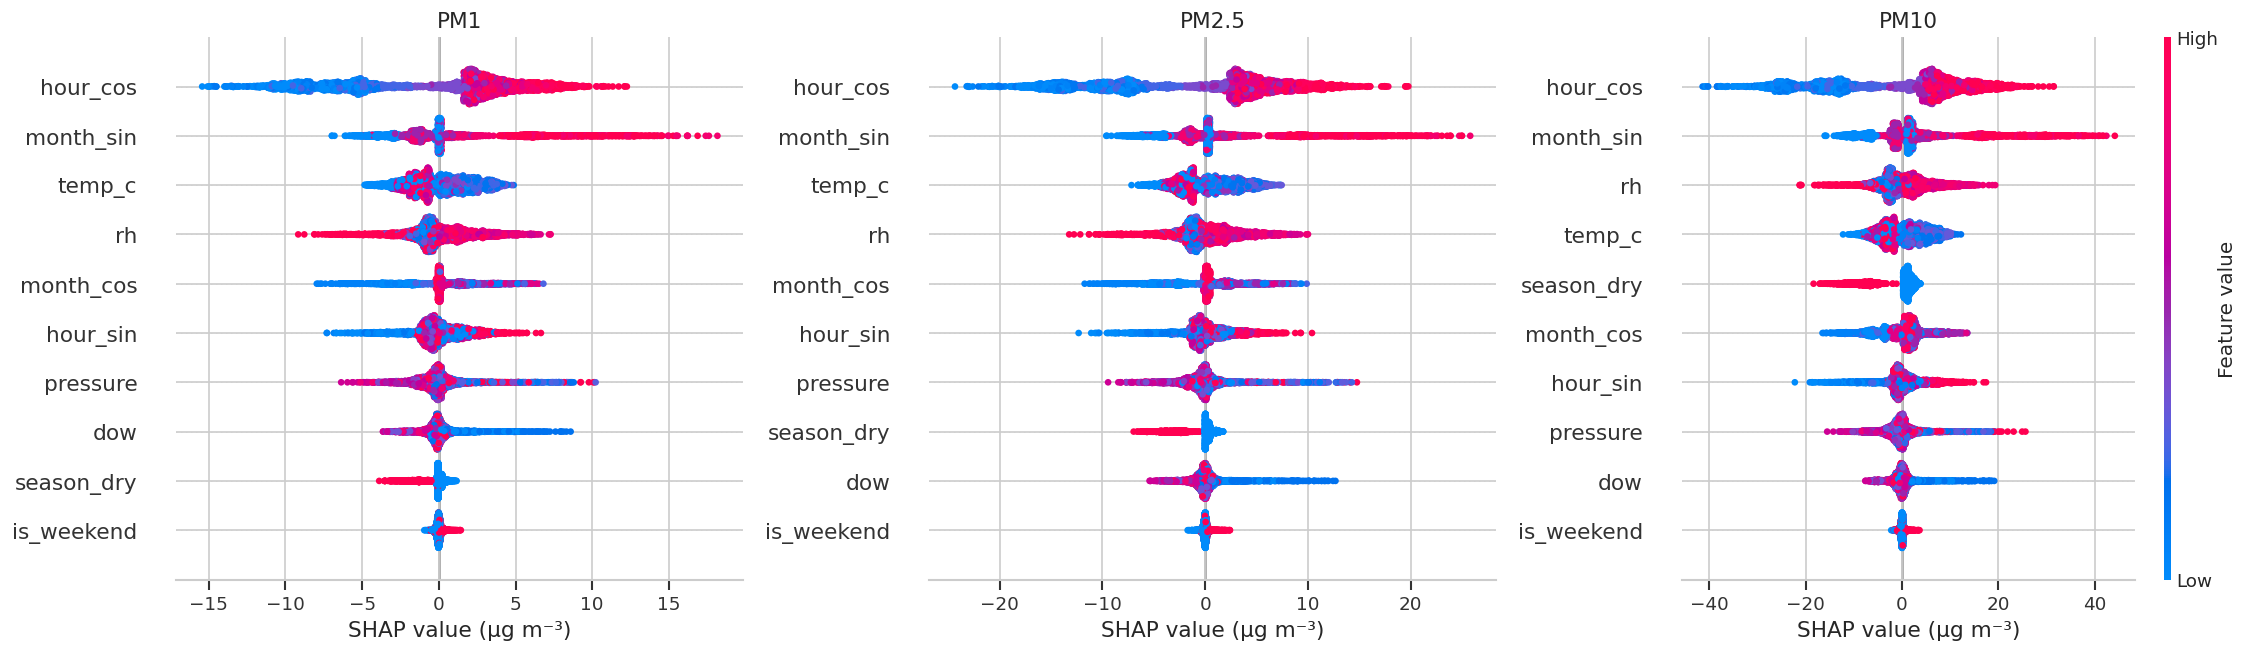

Realised feature ordering by fraction, for cross-checking against Table 3:
    pm1: hour_cos > month_sin > temp_c > rh > month_cos > hour_sin > pressure > dow > season_dry > is_weekend
   pm25: hour_cos > month_sin > temp_c > rh > month_cos > hour_sin > pressure > season_dry > dow > is_weekend
   pm10: hour_cos > month_sin > rh > temp_c > season_dry > month_cos > hour_sin > pressure > dow > is_weekend


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))

for ax, t in zip(axes, TARGETS):
    order = np.argsort(-np.abs(shap_pool[t]).mean(0))
    plt.sca(ax)
    shap.summary_plot(shap_pool[t][:, order], X_pool[t].iloc[:, order],
                      feature_names=[FEATURES[i] for i in order],
                      show=False, plot_size=None, color_bar=(t == "pm10"))
    ax.set_title(LABELS[t], fontsize=13)
    ax.set_xlabel(f"SHAP value ({UNIT})")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig9_beeswarm_all.png", dpi=220, bbox_inches="tight")
plt.show()

for t in TARGETS:                       # full-size panels for Appendix A
    order = np.argsort(-np.abs(shap_pool[t]).mean(0))
    plt.figure(figsize=(7.5, 5.2))
    shap.summary_plot(shap_pool[t][:, order], X_pool[t].iloc[:, order],
                      feature_names=[FEATURES[i] for i in order], show=False)
    plt.title(LABELS[t])
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/figA1_{t}.png", dpi=220, bbox_inches="tight")
    plt.close()

print("Realised feature ordering by fraction, for cross-checking against Table 3:")
for t in TARGETS:
    o = np.argsort(-np.abs(shap_pool[t]).mean(0))
    print(f"  {t:>5}: " + " > ".join(FEATURES[i] for i in o))

### 11.4 Feature importance across particle sizes

Table 3 as a chart. Because PM10 has larger absolute values than PM1, its bars are naturally longer; compare the **ranking** and **relative shares** of features rather than raw bar lengths.

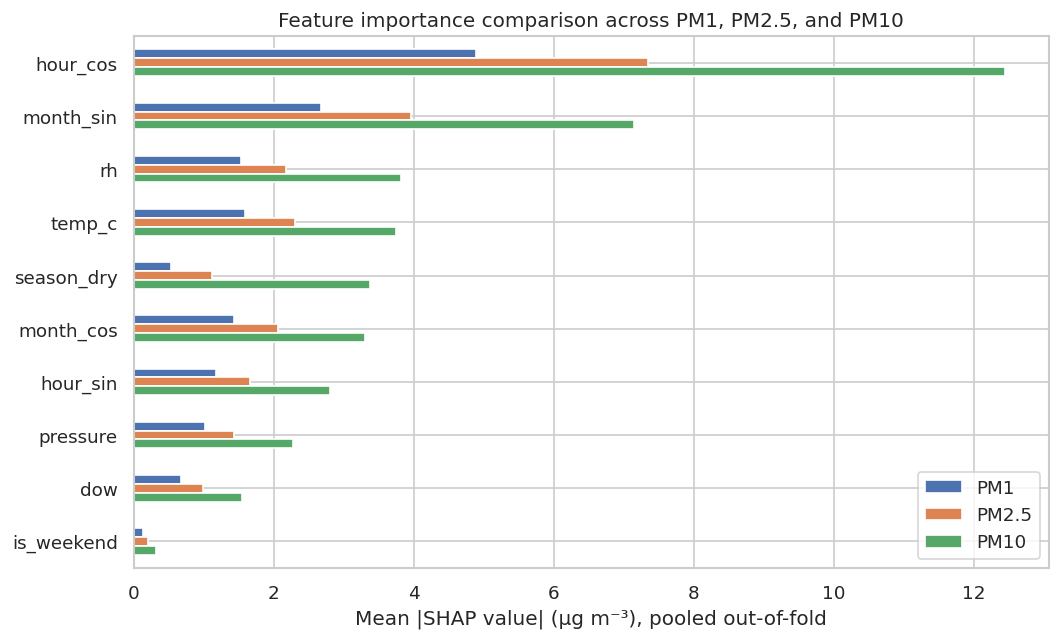

In [28]:
fig, ax = plt.subplots(figsize=(9, 5.5))
tab3.rename(columns=LABELS).plot(kind="barh", ax=ax)
ax.invert_yaxis()
ax.set_xlabel(f"Mean |SHAP value| ({UNIT}), pooled out-of-fold")
ax.set_title("Feature importance comparison across PM1, PM2.5, and PM10")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig10_shap_importance_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

### 11.5 Dependence plots for key features

How the model's output changes along the range of one feature, shown for relative humidity, temperature, and `hour_sin`, to probe the hypothesised meteorological and diurnal controls.

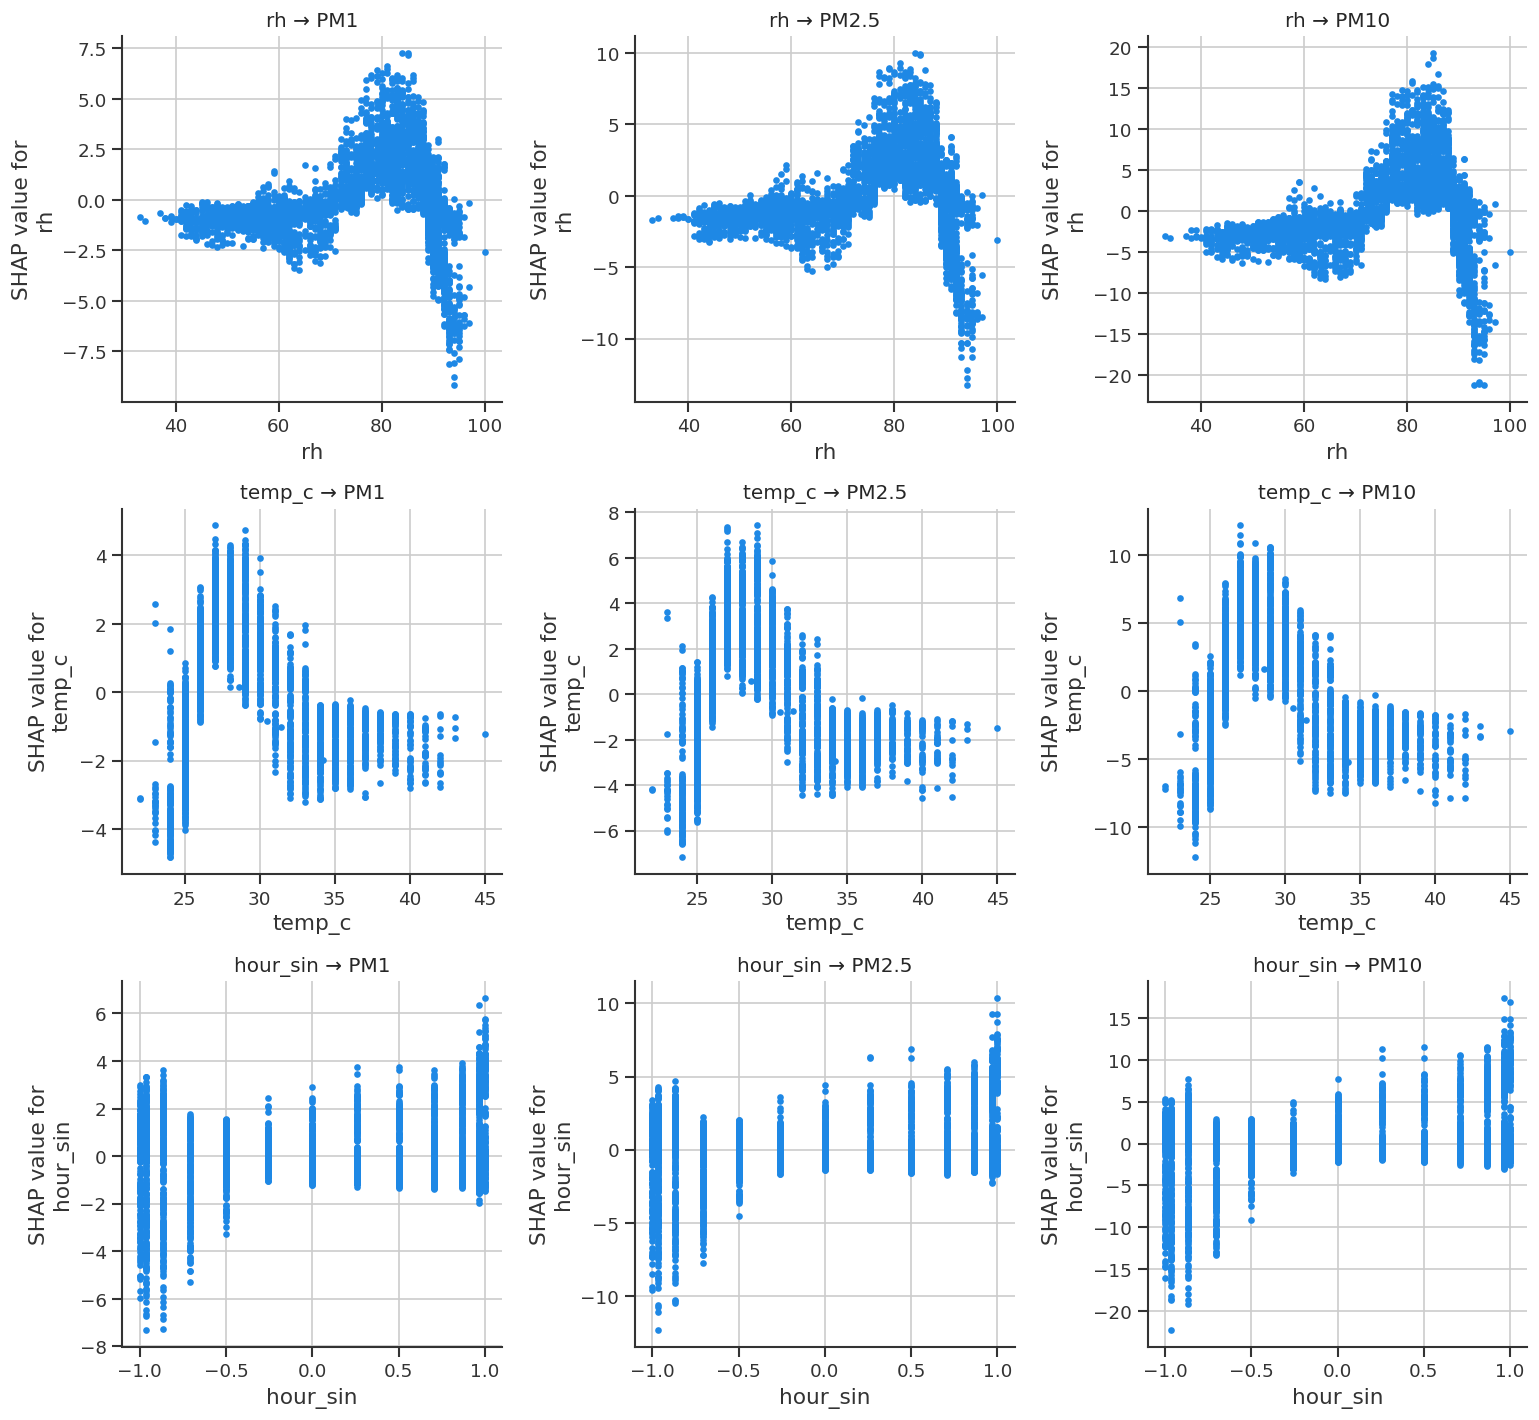

In [29]:
key_features = ["rh", "temp_c", "hour_sin"]

fig, axes = plt.subplots(len(key_features), len(TARGETS), figsize=(13, 4 * len(key_features)))
for i, feat in enumerate(key_features):
    for j, t in enumerate(TARGETS):
        shap.dependence_plot(feat, shap_pool[t], X_pool[t],
                             ax=axes[i, j], show=False, interaction_index=None)
        axes[i, j].set_title(f"{feat} → {LABELS[t]}")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/fig11_shap_dependence_key_features.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Instrumental artefact versus wet scavenging: a κ-Köhler test

> **Purpose.** Separate an instrumental explanation from a physical one for the SHAP feature near 88–90 % relative humidity.
> **Output.** `figA3_rh_kappa_sensitivity.png`.
> **What to check.** Whether the sign reversal near 88–90 % survives the correction (see the decision rule printed under the figure).

**Reviewer 1 comment 1.3 and Reviewer 3 comment 3.9.** The 88–90 % band is precisely the range in which hygroscopic bias in optical PM retrieval is strongest. Water uptake alters the optical diameter of the sampled particles, and the resulting distortion of inferred mass grows steeply as saturation is approached. A reversal in the SHAP dependence at that humidity is therefore an expected instrumental signature quite as much as an expected physical one, and the original manuscript did not distinguish the two.

The test corrects the optical concentrations by a κ-Köhler growth factor,

$$C_{\mathrm{dry}} = \frac{C_{\mathrm{measured}}}{1 + \kappa\,\dfrac{a_w}{1-a_w}},
\qquad a_w = \mathrm{RH}/100,$$

refits the Random Forest, and examines whether the feature persists, for three plausible values of κ. If the threshold disappears, the instrumental explanation is the more economical; if it survives, the physical reading is strengthened. The outcome populates the `‹present / attenuated / absent›` placeholder in Section 4 of the manuscript.

This test is **indicative rather than decisive**. A co-located gravimetric or dried-inlet reference would be required to settle the question, and the manuscript states as much.

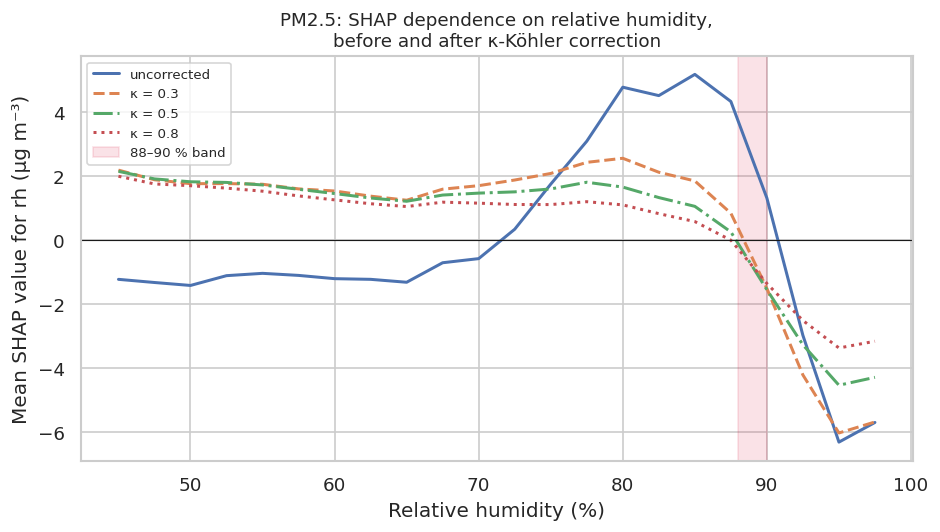

Assessment: does the sign reversal near 88-90% survive the correction?
  unchanged           -> 'present'      (physical reading strengthened)
  reduced but visible -> 'attenuated'   (both effects contribute)
  eliminated          -> 'absent'       (instrumental artefact most economical)


In [30]:
def kappa_correct(c, rh, kappa):
    aw = np.clip(rh, 0, 99.5) / 100.0
    return c / (1.0 + kappa * aw / (1.0 - aw))


def rh_dependence(t, kappa=None):
    """Return binned mean SHAP for rh, for the raw or kappa-corrected target."""
    y = y_all[t].copy()
    if kappa is not None:
        y = kappa_correct(y, X_all["rh"].values, kappa)
    m = fit_final("Random Forest", BEST[t]["Random Forest"],
                  Xtr_all, y[:n_train], RANDOM_STATE)
    Xsub = shap_subsample(Xte_all, RANDOM_STATE)
    sv = tree_shap(m, Xsub)[:, FEATURES.index("rh")]
    bins = np.arange(30, 101, 2.5)
    idx = np.digitize(Xsub["rh"].values, bins)
    g = pd.Series(sv).groupby(idx).mean()
    centres = [bins[min(i, len(bins) - 1)] for i in g.index]
    return np.array(centres), g.values


plt.figure(figsize=(8.0, 4.6))
for kappa, label, style in [(None, "uncorrected", "-"), (0.3, "κ = 0.3", "--"),
                            (0.5, "κ = 0.5", "-."), (0.8, "κ = 0.8", ":")]:
    c, v = rh_dependence("pm25", kappa)
    plt.plot(c, v, style, lw=1.8, label=label)
plt.axvspan(88, 90, color="crimson", alpha=.12, label="88–90 % band")
plt.axhline(0, color="k", lw=.7)
plt.xlabel("Relative humidity (%)")
plt.ylabel(f"Mean SHAP value for rh ({UNIT})")
plt.title("PM2.5: SHAP dependence on relative humidity,\nbefore and after κ-Köhler correction", fontsize=11)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figA3_rh_kappa_sensitivity.png", dpi=220, bbox_inches="tight")
plt.show()

print("Assessment: does the sign reversal near 88-90% survive the correction?")
print("  unchanged           -> 'present'      (physical reading strengthened)")
print("  reduced but visible -> 'attenuated'   (both effects contribute)")
print("  eliminated          -> 'absent'       (instrumental artefact most economical)")

## 13. Permutation control for the `dow` attribution

> **Purpose.** Test whether the SHAP value of `dow` (day of week) is meaningful or just noise absorbed by a low-cardinality feature.
> **Output.** The `dow`-to-`noise` ratio per fraction.
> **What to check.** A ratio close to 1 means `dow` should not be interpreted mechanistically.

**Reviewer 3, comment 3.11.** The observed weekly cycle is negligible (Section 4.4), yet `dow` carries a larger mean absolute SHAP value than `season_dry` for the finer fractions. The most economical reading is that the ensembles absorb residual, unstructured variance into a low-cardinality calendar feature.

To place that reading on firmer ground than assertion, a pure random feature (`noise`) is injected alongside the genuine predictors. A `dow`-to-`noise` ratio approaching unity indicates that the attribution carried by `dow` is consistent with noise absorption.

In [31]:
rng = np.random.default_rng(RANDOM_STATE)
Xn = X_all.copy()
Xn["noise"] = rng.normal(size=len(Xn))

for t in TARGETS:
    y = y_all[t]
    m = fit_final("Random Forest", BEST[t]["Random Forest"],
                  Xn.iloc[:n_train], y[:n_train], RANDOM_STATE)
    sv = np.abs(tree_shap(m, shap_subsample(Xn.iloc[n_train:], RANDOM_STATE))).mean(0)
    s = pd.Series(sv, index=list(Xn.columns))
    print(f"{t:>5}: dow {s['dow']:6.3f} | noise {s['noise']:6.3f} | "
          f"season_dry {s['season_dry']:6.3f} | "
          f"dow-to-noise ratio {s['dow'] / max(s['noise'], 1e-9):5.2f}")

print("\nA ratio close to unity supports the noise-absorption reading given in")
print("Section 3.5 of the manuscript.")

  pm1: dow  0.215 | noise  0.260 | season_dry  2.133 | dow-to-noise ratio  0.83
 pm25: dow  0.268 | noise  0.360 | season_dry  3.843 | dow-to-noise ratio  0.75
 pm10: dow  0.379 | noise  0.666 | season_dry 10.553 | dow-to-noise ratio  0.57

A ratio close to unity supports the noise-absorption reading given in
Section 3.5 of the manuscript.


# Part E. Output

## 14. Results summary and export

> **Purpose.** Collect the key numbers in one place, write the manuscript-ready tables, and package everything for download.
> **Output.** `table2_for_paper.csv`, `results_summary.csv`, and (in Colab) `analysis_results.zip`.

### 14.1 Table 2 for the manuscript

Writes `table2_for_paper.csv` with exactly the columns of Table 2 in the manuscript: fraction, model, RMSE, MAE, R² (window baseline, tuned models), and rolling-origin RMSE as mean ± standard deviation.

In [32]:
hold = tab2.query("Config == 'tuned'").set_index(["Fraction", "Model"])
cvm  = summary.set_index(["Fraction", "Model"])

table2_paper = pd.DataFrame({
    "RMSE": hold["RMSE"],
    "MAE": hold["MAE"],
    "R2": hold["R2_window"],
    "RMSE_CV_mean_sd": cvm["RMSE_CV"],
}).reset_index()

frac_order = {"pm1": 0, "pm25": 1, "pm10": 2}
model_order = {name: i for i, name in enumerate(LEARNER_NAMES)}
table2_paper = table2_paper.sort_values(
    ["Fraction", "Model"],
    key=lambda s: s.map(frac_order) if s.name == "Fraction" else s.map(model_order))
table2_paper["Fraction"] = table2_paper["Fraction"].map(LABELS)
table2_paper.to_csv(f"{OUTPUT_DIR}/table2_for_paper.csv", index=False)
table2_paper.reset_index(drop=True)

,Fraction,Model,RMSE,MAE,R2,RMSE_CV_mean_sd
0,PM1,Random Forest,14.32,7.59,0.206,23.27 +/- 13.04
1,PM1,LightGBM,14.75,8.66,0.158,22.9 +/- 13.47
2,PM1,XGBoost,14.47,8.28,0.190,23.01 +/- 13.75
3,PM2.5,Random Forest,20.99,10.73,0.194,34.29 +/- 19.71
4,PM2.5,LightGBM,21.40,11.65,0.162,33.73 +/- 20.09
5,PM2.5,XGBoost,21.29,11.97,0.170,34.16 +/- 20.35
6,PM10,Random Forest,36.81,18.13,0.169,59.43 +/- 34.85
7,PM10,LightGBM,37.08,20.10,0.157,58.82 +/- 35.64
8,PM10,XGBoost,36.68,18.81,0.175,58.59 +/- 35.92


### 14.2 One-page summary

For each fraction: the best learner on the primary hold-out, its performance, and the three most influential features from the pooled out-of-fold attribution (Table 3). The cell updates automatically if the data or settings change.

In [33]:
rows = []
for t in TARGETS:
    best = tab2.query("Fraction == @t and Config == 'tuned'").sort_values("R2_window").iloc[-1]
    cv_row = summary.query("Fraction == @t and Model == @best['Model']").iloc[0]
    top3 = tab3[t].nlargest(3)
    rows.append({
        "Fraction": LABELS[t],
        "Best learner (hold-out)": best["Model"],
        "R2_window": best["R2_window"],
        "RMSE": best["RMSE"],
        "RMSE rolling-origin": cv_row["RMSE_CV"],
        "Meteorological share (%)": round(float(shares[t]["met"].mean()), 1),
        "Top 3 features (mean |SHAP|)": ", ".join(f"{f} ({v:.2f})" for f, v in top3.items()),
    })

summary_df = pd.DataFrame(rows)
summary_df.to_csv(f"{OUTPUT_DIR}/results_summary.csv", index=False)
summary_df

,Fraction,Best learner (hold-out),R2_window,RMSE,RMSE rolling-origin,Meteorological share (%),Top 3 features (mean |SHAP|)
0,PM1,Random Forest,0.206,14.32,23.27 +/- 13.04,26.4,"hour_cos (4.89), month_sin (2.68), temp_c (1.59)"
1,PM2.5,Random Forest,0.194,20.99,34.29 +/- 19.71,25.4,"hour_cos (7.34), month_sin (3.96), temp_c (2.30)"
2,PM10,XGBoost,0.175,36.68,58.59 +/- 35.92,24.1,"hour_cos (12.45), month_sin (7.15), rh (3.82)"


### 14.3 How to interpret and report these results

Use the tables and figures to address the following questions in the manuscript:

- Which features dominate for PM10 and PM2.5? Do they point to time-of-day activity (e.g., traffic, road-dust resuspension)?
- Which features dominate for PM1? Do temperature and humidity play a larger relative role, as expected for secondary or hygroscopic processes?
- Is the pattern consistent with the hypothesis stated in the abstract?

**Caveats to state alongside the findings**

- **Model skill.** Check the R² values (Section 8 and the summary above). When R² is low, the models capture only part of the variability, and SHAP rankings describe the model's behaviour rather than established causes.
- **Learner ranking.** Where the paired intervals in Section 9.2 contain zero, no learner should be declared better than another.
- **Temporal coverage.** The primary hold-out is the *last* part of the timeline and lies within a single season. Months that appear only in the hold-out were never seen in training, and month-based features cannot extrapolate to them. This is why attribution is taken out-of-fold (Section 11).
- **Correlated features and targets.** SHAP shares credit among correlated features, and the three targets are near-collinear optical channels, so the per-fraction models are not independent analyses.
- **Instrument limits.** Optical PM retrieval is hygroscopically biased at high humidity and radiatively affected at high temperature (Sections 3.3, 10, 12). A co-located gravimetric or dried-inlet reference would be needed to settle the humidity question.

### 14.4 List and package the outputs

Lists every file written to `outputs/`. In Google Colab, the folder is also zipped and downloaded; when running locally, simply take the files from the `outputs/` folder.

In [34]:
print("Files written to outputs/:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print("  -", f)

try:
    from google.colab import files
    shutil.make_archive("analysis_results", "zip", OUTPUT_DIR)
    files.download("analysis_results.zip")
except ImportError:
    pass  # running locally

Files written to outputs/:
  - best_hyperparameters.json
  - cv_raw_runs.csv
  - fig01_missing_data_pattern.png
  - fig02_timeseries_pm.png
  - fig03_distribution_pm.png
  - fig04_diurnal_pattern.png
  - fig05_weekly_pattern.png
  - fig06_correlation_heatmap.png
  - fig07_model_comparison_r2.png
  - fig08_prediction_vs_observed.png
  - fig10_shap_importance_comparison.png
  - fig11_shap_dependence_key_features.png
  - fig9_beeswarm_all.png
  - figA1_pm1.png
  - figA1_pm10.png
  - figA1_pm25.png
  - figA2_temperature_qc.png
  - figA3_rh_kappa_sensitivity.png
  - results_summary.csv
  - table1_descriptive.csv
  - table2_cv_summary.csv
  - table2_for_paper.csv
  - table2_holdout.csv
  - table3_shap.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>